# Predicción de mora en préstamos hipotecarios

Proyecto Final Integrador · Diplomatura en Ciencia de Datos y Análisis Avanzado (UTN BA)

Grupo 24: Ailin Soriano, Fernanda Pardo, Pablo Magnino, Germán Langoni

**Objetivo:** estimar la probabilidad de que una solicitud de crédito hipotecario entre en mora y usarla para decidir si se aprueba o se rechaza.

Seguimos CRISP-DM: 1. Negocio · 2. Datos y EDA · 3. Preparación · 4. Modelado · 5. Evaluación · 6. Aporte de cada variable · 7. Interpretación · 8. Impacto, riesgos y ética · 9. Conclusiones.

Las librerías están en `requirements.txt`. El notebook tarda unos 10-15 minutos. En Colab, si no encuentra `data/Loan_Default.csv`, descarga el archivo del repositorio.

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score, f1_score, accuracy_score,
                             precision_recall_curve)
from xgboost import XGBClassifier
import shap

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# ---------------------------------------------------------------- rutas
def _buscar_raiz():
    for cand in [".", "..", "../.."]:
        if os.path.isdir(os.path.join(cand, "data")):
            return os.path.abspath(cand)
    return os.path.abspath(".")

RAIZ = _buscar_raiz()
# El dataset puede estar como CSV o comprimido en zip (así está en el repositorio)
DATA = next((os.path.join(RAIZ, "data", f) for f in ["Loan_Default.csv", "Loan_Default.zip"]
             if os.path.exists(os.path.join(RAIZ, "data", f))), None)
# Si no está en la carpeta data/ (por ejemplo, en Colab), se descarga del repositorio
URL_DATOS = "https://raw.githubusercontent.com/pabloamagnino-coder/grupo24-utn-tpfinal/main/data/Loan_Default.zip"
FIG = os.path.join(RAIZ, "outputs", "final", "figures")
TAB = os.path.join(RAIZ, "outputs", "final", "tables")
os.makedirs(FIG, exist_ok=True)
os.makedirs(TAB, exist_ok=True)

# ---------------------------------------------------------------- semillas
RANDOM_STATE = 42             # split train/test y folds de CV
SEMILLAS = [1, 2, 3, 4, 5]    # semillas por modelo, para medir la variabilidad

# ---------------------------------------------------------------- estilo de los gráficos
# Colores de los gráficos
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
VIOLETA, ROJO = "#4a3aa7", "#e34948"
TINTA, TINTA2, GRIS, GRILLA = "#0b0b0b", "#52514e", "#a3a29c", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": TINTA2, "axes.edgecolor": GRIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "legend.frameon": False,
    "lines.linewidth": 2,
})

def usd_m(x, _=None):
    return f"{x/1e6:,.0f} M".replace(",", ".")

def plata(x):
    s = f"{abs(x):,.0f}".replace(",", ".")
    return f"-USD {s}" if x < 0 else f"USD {s}"

def guardar(fig, nombre):
    fig.savefig(os.path.join(FIG, nombre))
    plt.show()

def tabla(df, nombre, index=False):
    df.to_csv(os.path.join(TAB, nombre), index=index)
    return df

---
# 1. Comprensión del negocio

## 1.1 La decisión

Cuando llega una solicitud de crédito hipotecario, el área de riesgo tiene que aprobarla o rechazarla. El modelo estima la probabilidad de mora y una regla económica la convierte en una decisión. Los usuarios son los analistas de riesgo; el afectado es el solicitante, que tiene derecho a saber por qué lo rechazaron.

## 1.2 Los dos errores

| Situación | Error | Costo para el banco |
|---|---|---|
| Aprobar a quien no paga | Falso negativo | La parte del capital que no recupera al ejecutar la garantía |
| Rechazar a quien habría pagado | Falso positivo | El margen del crédito |

Una mora cuesta varias veces lo que deja un crédito sano, pero rechazar de más también tiene un costo. Por eso evaluamos el resultado en dólares y no la accuracy (predecir siempre "no mora" ya da 84%).

## 1.3 Objetivos, fijados antes de modelar

- PR-AUC en test de al menos el doble de la tasa de mora.
- Mejor resultado económico que la mejor regla simple con LTV y deuda/ingreso, con un intervalo de confianza que no incluya el cero.
- No rechazar más del 20% de las solicitudes.

## 1.4 Hipótesis

- **H1, capacidad de pago:** más deuda sobre ingreso y menos ingreso, más mora.
- **H2, garantía:** más LTV, más mora.
- **H3, tipo de producto:** el pago global al final, la amortización negativa o el destino comercial aumentan el riesgo.
- **H4, historial:** menor `Credit_Score`, más mora.

---
# 2. Comprensión de los datos

[Loan Default Dataset](https://www.kaggle.com/datasets/yasserh/loan-default-dataset) (Kaggle): una fila por solicitud de crédito hipotecario, año 2019, sin datos personales identificables.

In [2]:
if DATA:
    crudo = pd.read_csv(DATA)
else:
    print("No se encontró el dataset en data/; descargando desde", URL_DATOS)
    crudo = pd.read_csv(URL_DATOS, compression="zip")

TARGET = "Status"
print(f"Filas: {len(crudo):,}   Columnas: {crudo.shape[1]}")
print(f"Duplicados exactos: {crudo.duplicated().sum()}   ID único: {crudo['ID'].is_unique}")
print(f"Años presentes: {sorted(crudo['year'].unique())}")
print(f"Tasa de mora: {crudo[TARGET].mean():.2%}")

Filas: 148,670   Columnas: 34


Duplicados exactos: 0   ID único: True
Años presentes: [np.int64(2019)]
Tasa de mora: 24.64%


## 2.1 Variables principales

| Variable | Qué es | Uso |
|---|---|---|
| `loan_amount` | Monto del préstamo (USD) | Predictora |
| `property_value` | Tasación de la propiedad (USD) | Predictora (H2) |
| `LTV` | Préstamo / tasación × 100 | Predictora (H2) |
| `income` | Ingreso mensual del solicitante | Predictora (H1) |
| `dtir1` | Deuda total / ingreso (%) | Predictora (H1) |
| `Credit_Score` | Puntaje crediticio (500-900) | Predictora (H4) |
| `Credit_Worthiness` | Calificación del originador (l1/l2) | Excluida (6.1) |
| `lump_sum_payment` | Pago global al final del crédito | Predictora (H3) |
| `credit_type` | Buró que informó el historial | Ver 2.3 |
| `Status` | 1 = mora, 0 = al día | Objetivo |

`income` es mensual: con un ingreso anual de USD 5.760 nadie accede a un préstamo de USD 300.000, y con ingreso mensual la relación deuda/ingreso mediana (38%) es coherente. El diccionario de Kaggle no lo aclara. El glosario completo está en `data/glosario_variables.md`.

In [3]:
print("Medianas:", crudo[["loan_amount", "income", "dtir1", "LTV"]].median().round(1).to_dict())

Medianas: {'loan_amount': 296500.0, 'income': 5760.0, 'dtir1': 39.0, 'LTV': 75.1}


## 2.2 Valores faltantes

In [4]:
calidad = pd.DataFrame({
    "nulos": crudo.isna().sum(),
    "% nulos": (crudo.isna().mean() * 100).round(2),
    "% nulos si mora": (crudo[crudo[TARGET] == 1].isna().mean() * 100).round(2),
    "% nulos si al día": (crudo[crudo[TARGET] == 0].isna().mean() * 100).round(2),
}).query("nulos > 0").sort_values("% nulos", ascending=False)
tabla(calidad, "t01_nulos.csv", index=True)

,nulos,% nulos,% nulos si mora,% nulos si al día
Upfront_charges,39642,26.6600,99.5800,2.8200
Interest_rate_spread,36639,24.6400,100.0000,0.0000
rate_of_interest,36439,24.5100,99.4500,0.0000
dtir1,24121,16.2200,44.5200,6.9700
property_value,15098,10.1600,41.2000,0.0000
LTV,15098,10.1600,41.2000,0.0000
income,9150,6.1500,3.3800,7.0600
loan_limit,3344,2.2500,2.4000,2.2000
approv_in_adv,908,0.6100,0.6600,0.6000
submission_of_application,200,0.1300,0.5500,0.0000


`rate_of_interest`, `Interest_rate_spread` y `Upfront_charges` están vacías en casi todas las moras y casi nunca en el resto. Son condiciones que se fijan después de aprobar el crédito y su ausencia delata el resultado, así que las excluimos.

## 2.3 Un bloque de solicitudes con 100% de mora

Buscamos categorías con una tasa de mora extrema:

In [5]:
NUMERICAS_CRUDAS = ["ID", "year", "loan_amount", "rate_of_interest", "Interest_rate_spread",
                    "Upfront_charges", "term", "property_value", "income", "Credit_Score",
                    "LTV", "dtir1", TARGET]
extremos = []
for col in [c for c in crudo.columns if c not in NUMERICAS_CRUDAS]:
    g = crudo.groupby(col, dropna=False)[TARGET].agg(["mean", "size"])
    for cat, fila in g.iterrows():
        if fila["mean"] > 0.95:
            extremos.append({"variable": col, "categoría": "(vacío)" if pd.isna(cat) else cat,
                             "solicitudes": int(fila["size"]), "tasa de mora": fila["mean"]})
for col in ["property_value", "LTV"]:
    s = crudo.loc[crudo[col].isna(), TARGET]
    extremos.append({"variable": col, "categoría": "(vacío)", "solicitudes": len(s),
                     "tasa de mora": s.mean()})
extremos = tabla(pd.DataFrame(extremos), "t02_segmentos_100pct_mora.csv")
extremos

,variable,categoría,solicitudes,tasa de mora
0,construction_type,mh,33,1.0000
1,Secured_by,land,33,1.0000
2,credit_type,EQUI,15298,0.9999
3,age,(vacío),200,1.0000
4,submission_of_application,(vacío),200,1.0000
5,Security_Type,Indriect,33,1.0000
6,property_value,(vacío),15098,0.9999
7,LTV,(vacío),15098,0.9999


In [6]:
eq = crudo["credit_type"] == "EQUI"
sin_tasacion = crudo["property_value"].isna()
print(f"credit_type = EQUI:                   {eq.sum():>6,}")
print(f"sin tasación (property_value vacío):  {sin_tasacion.sum():>6,}")
print(f"ambas cosas a la vez:                 {(eq & sin_tasacion).sum():>6,}")
print(f"moras totales del dataset:            {crudo[TARGET].sum():>6,}")
print(f"moras dentro de EQUI o sin tasación:  {crudo.loc[eq | sin_tasacion, TARGET].sum():>6,}"
      f"  ({crudo.loc[eq | sin_tasacion, TARGET].sum() / crudo[TARGET].sum():.0%} de todas)")

credit_type = EQUI:                   15,298
sin tasación (property_value vacío):  15,098
ambas cosas a la vez:                 15,096
moras totales del dataset:            36,639
moras dentro de EQUI o sin tasación:  15,297  (42% de todas)


Las solicitudes del buró EQUI (Equifax) y las que no tienen tasación son casi las mismas (15.096 en común), están todas en mora y explican el 42% de las moras del dataset. No parece una señal real: ningún grupo de clientes entra en mora el 100% de las veces, y un banco no otorga un hipotecario sin tasar la propiedad. Lo más probable es que estos registros se hayan cargado de otra forma. Si el modelo los ve, aprende a reconocer el bloque en lugar de evaluar el riesgo.

Al sacarlos también desaparece la relación entre `dtir1` vacío y mora:

In [7]:
artefacto = (eq | sin_tasacion | crudo["age"].isna() | (crudo["Secured_by"] == "land"))
limpio_tmp = crudo[~artefacto]
comp = pd.DataFrame({
    "% nulos dtir1 — dataset completo": crudo.groupby(TARGET)["dtir1"].apply(lambda s: s.isna().mean() * 100),
    "% nulos dtir1 — sin el bloque": limpio_tmp.groupby(TARGET)["dtir1"].apply(lambda s: s.isna().mean() * 100),
}).round(1)
comp.index = ["al día", "mora"]
comp

,% nulos dtir1 — dataset completo,% nulos dtir1 — sin el bloque
al día,7.0000,7.0000
mora,44.5000,4.7000


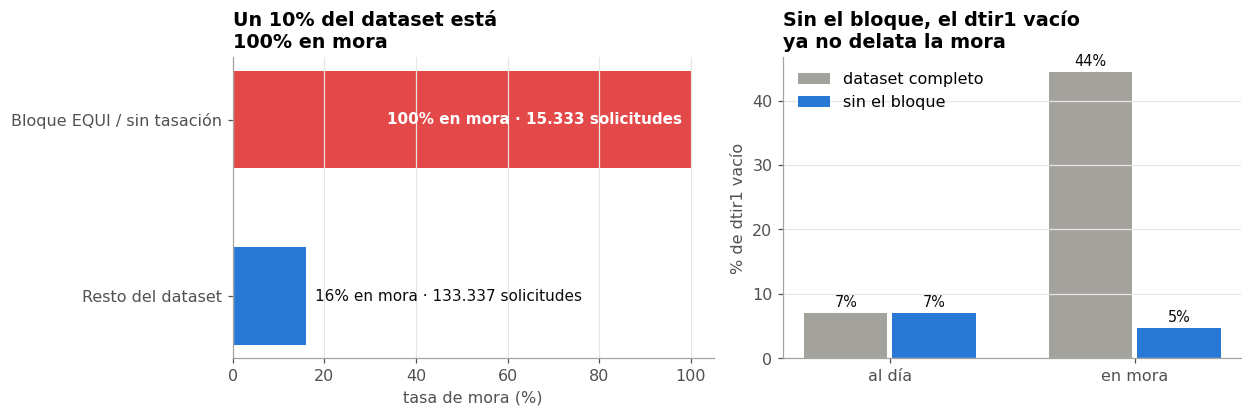

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1.05, 1]})
segm = pd.DataFrame({
    "segmento": ["Bloque EQUI / sin tasación", "Resto del dataset"],
    "solicitudes": [int(artefacto.sum()), int((~artefacto).sum())],
    "tasa": [crudo.loc[artefacto, TARGET].mean(), crudo.loc[~artefacto, TARGET].mean()],
})
ax = axes[0]
ax.barh(segm["segmento"][::-1], segm["tasa"][::-1] * 100, color=[AZUL, ROJO], height=0.55)
for i, (t, n) in enumerate(zip(segm["tasa"][::-1], segm["solicitudes"][::-1])):
    txt = f"{t:.0%} en mora · {n:,} solicitudes".replace(",", ".")
    if t > 0.5:
        ax.text(t * 100 - 2, i, txt, va="center", ha="right", color="white", fontsize=10, fontweight="bold")
    else:
        ax.text(t * 100 + 2, i, txt, va="center", color=TINTA, fontsize=10)
ax.set_xlim(0, 105); ax.set_xlabel("tasa de mora (%)"); ax.grid(axis="y", visible=False)
ax.set_title("Un 10% del dataset está\n100% en mora")

ax = axes[1]
x = np.arange(2)
ax.bar(x - 0.18, comp.iloc[:, 0], 0.34, color=GRIS, label="dataset completo")
ax.bar(x + 0.18, comp.iloc[:, 1], 0.34, color=AZUL, label="sin el bloque")
for xi, v in zip(np.r_[x - 0.18, x + 0.18], np.r_[comp.iloc[:, 0], comp.iloc[:, 1]]):
    ax.text(xi, v + 1, f"{v:.0f}%", ha="center", fontsize=9.5, color=TINTA)
ax.set_xticks(x, ["al día", "en mora"]); ax.set_ylabel("% de dtir1 vacío")
ax.set_title("Sin el bloque, el dtir1 vacío\nya no delata la mora")
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "f01_bloque_artefacto.png")

## 2.4 EDA de las hipótesis

Sin el bloque (ver 3.1), la tasa de mora es 16,0%.

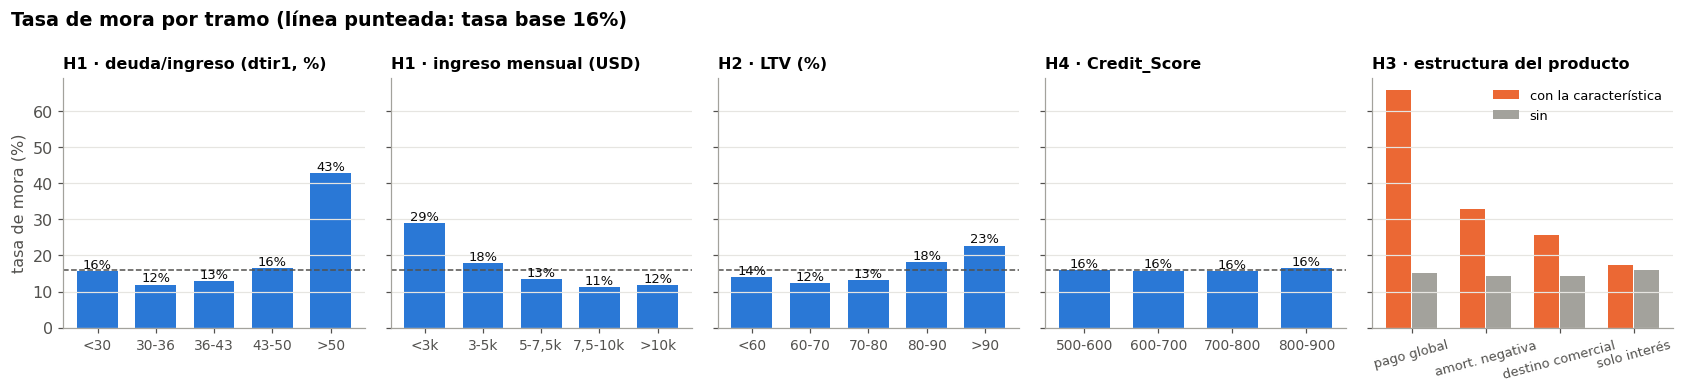

In [9]:
v = limpio_tmp.copy()
tasa_base = v[TARGET].mean()

def tasa_por_tramo(serie, bins, etiquetas):
    tramo = pd.cut(serie, bins=bins, labels=etiquetas, include_lowest=True)
    return v.groupby(tramo, observed=True)[TARGET].agg(["mean", "size"])

eda = {
    "H1 · deuda/ingreso (dtir1, %)": tasa_por_tramo(v["dtir1"], [0, 30, 36, 43, 50, 100], ["<30", "30-36", "36-43", "43-50", ">50"]),
    "H1 · ingreso mensual (USD)": tasa_por_tramo(v["income"], [-1, 3000, 5000, 7500, 10000, 1e9], ["<3k", "3-5k", "5-7,5k", "7,5-10k", ">10k"]),
    "H2 · LTV (%)": tasa_por_tramo(v["LTV"], [0, 60, 70, 80, 90, 1e6], ["<60", "60-70", "70-80", "80-90", ">90"]),
    "H4 · Credit_Score": tasa_por_tramo(v["Credit_Score"], [499, 600, 700, 800, 900], ["500-600", "600-700", "700-800", "800-900"]),
}
prod = []
for col, val, nombre in [("lump_sum_payment", "lpsm", "pago global"), ("Neg_ammortization", "neg_amm", "amort. negativa"),
                         ("business_or_commercial", "b/c", "destino comercial"), ("interest_only", "int_only", "solo interés")]:
    prod.append({"tramo": nombre, "con": v.loc[v[col] == val, TARGET].mean(), "sin": v.loc[v[col] != val, TARGET].mean(),
                 "n": int((v[col] == val).sum())})
prod = pd.DataFrame(prod)

fig, axes = plt.subplots(1, 5, figsize=(15.5, 3.6), sharey=True)
for ax, (titulo, t) in zip(axes[:4], eda.items()):
    ax.bar(range(len(t)), t["mean"] * 100, color=AZUL, width=0.7)
    ax.axhline(tasa_base * 100, color=TINTA2, ls="--", lw=1)
    ax.set_xticks(range(len(t)), t.index, fontsize=9)
    ax.set_title(titulo, fontsize=10.5); ax.grid(axis="x", visible=False)
    for i, m in enumerate(t["mean"]):
        ax.text(i, m * 100 + 0.8, f"{m:.0%}", ha="center", fontsize=8.5, color=TINTA)
ax = axes[4]
ax.bar(np.arange(4) - 0.18, prod["con"] * 100, 0.34, color=NARANJA, label="con la característica")
ax.bar(np.arange(4) + 0.18, prod["sin"] * 100, 0.34, color=GRIS, label="sin")
ax.set_xticks(range(4), prod["tramo"], fontsize=8.5, rotation=15)
ax.set_title("H3 · estructura del producto", fontsize=10.5); ax.grid(axis="x", visible=False)
ax.legend(fontsize=8.5, loc="upper right")
axes[0].set_ylabel("tasa de mora (%)")
fig.suptitle(f"Tasa de mora por tramo (línea punteada: tasa base {tasa_base:.0%})", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold")
fig.tight_layout()
guardar(fig, "f02_eda_hipotesis.png")

In [10]:
for titulo, t in eda.items():
    print(titulo, " | ".join(f"{i}: {m:.1%}" for i, m in t["mean"].items()))
print(prod.round(3).to_string(index=False))

H1 · deuda/ingreso (dtir1, %) <30: 15.6% | 30-36: 11.9% | 36-43: 13.0% | 43-50: 16.5% | >50: 42.7%
H1 · ingreso mensual (USD) <3k: 28.9% | 3-5k: 17.9% | 5-7,5k: 13.4% | 7,5-10k: 11.3% | >10k: 11.8%
H2 · LTV (%) <60: 13.9% | 60-70: 12.4% | 70-80: 13.1% | 80-90: 18.2% | >90: 22.7%
H4 · Credit_Score 500-600: 16.0% | 600-700: 15.8% | 700-800: 15.6% | 800-900: 16.5%
            tramo    con    sin     n
      pago global 0.6590 0.1510  2215
  amort. negativa 0.3290 0.1420 12491
destino comercial 0.2570 0.1440 18297
     solo interés 0.1720 0.1590  6244


### Conclusiones del EDA

- **H1 se ve claro:** la mora sube fuerte con deuda/ingreso mayor a 50% y baja a medida que sube el ingreso.
- **H2 se ve, más suave:** la mora sube a partir de un LTV de 80%.
- **H3 es la señal más fuerte:** los créditos con pago global al final tienen 66% de mora, contra 15% del resto.
- **H4 no se ve:** la mora es la misma en todos los tramos de `Credit_Score`. En un banco real sería una de las variables más útiles, lo que sugiere que el dataset es en parte sintético.
- Ninguna variable sola separa bien las clases (AUC máximo 0,61): la señal está en las combinaciones.

---
# 3. Preparación de los datos

## 3.1 Filas excluidas

In [11]:
filas_excluidas = tabla(pd.DataFrame([
    {"criterio": "credit_type = EQUI o property_value vacío", "filas": int((eq | sin_tasacion).sum()),
     "motivo": "Bloque con 100% de mora: artefacto de construcción del dataset (sección 2.4)"},
    {"criterio": "age vacío (y submission_of_application vacío)", "filas": int((crudo['age'].isna() & ~(eq | sin_tasacion)).sum()),
     "motivo": "200 filas, todas en mora: mismo tipo de artefacto"},
    {"criterio": "Secured_by = land (construction_type = mh, Security_Type = Indriect)", "filas": int(((crudo['Secured_by'] == 'land') & ~(eq | sin_tasacion | crudo['age'].isna())).sum()),
     "motivo": "33 filas, todas en mora: mismo tipo de artefacto"},
]), "t03_filas_excluidas.csv")
datos = crudo[~artefacto].reset_index(drop=True)
print(f"Filas excluidas en total: {artefacto.sum():,} ({artefacto.mean():.1%})")
print(f"Filas para modelar:       {len(datos):,}   tasa de mora {datos[TARGET].mean():.2%}")
filas_excluidas

Filas excluidas en total: 15,333 (10.3%)
Filas para modelar:       133,337   tasa de mora 15.98%


,criterio,filas,motivo
0,credit_type = EQUI o property_value vacío,15300,Bloque con 100% de mora: artefacto de construc...
1,age vacío (y submission_of_application vacío),0,"200 filas, todas en mora: mismo tipo de artefacto"
2,"Secured_by = land (construction_type = mh, Sec...",33,"33 filas, todas en mora: mismo tipo de artefacto"


En la práctica, una solicitud sin tasación no se evaluaría con el modelo: iría a revisión manual.

## 3.2 Columnas excluidas

| Columna | Motivo |
|---|---|
| `ID`, `year` | Identificador y valor constante |
| `rate_of_interest`, `Interest_rate_spread`, `Upfront_charges` | Delatan el resultado (2.2) |
| `construction_type`, `Secured_by`, `Security_Type` | Quedan constantes después de sacar el bloque |
| `Gender`, `age` | Atributos protegidos: solo se usan para auditar (8.3) |
| `Credit_Worthiness` | Puede ser la calificación del sistema actual del banco; aporta menos del 1% (6.1) |
| `submission_of_application` | No sabemos qué mide, así que no podríamos justificar un rechazo basado en ella (6.1) |

`Region` queda como predictora y también se audita en 8.3.

## 3.3 Faltantes

| Variable | % vacío | Tratamiento |
|---|---|---|
| `dtir1`, `income` | 6,6% y 6,7% | Boosting: el modelo maneja el vacío solo. Logística: mediana + indicador de faltante |
| `loan_limit`, `approv_in_adv`, `loan_purpose`, `Neg_ammortization` | menos de 2,5% | Logística: categoría más frecuente. Boosting: categoría propia |
| `income = 0` | 348 filas | Se conservan y se marcan con una variable indicadora |

Las imputaciones se ajustan solo con los datos de entrenamiento, dentro del pipeline.

## 3.4 Outliers

No se eliminan: montos e ingresos altos son casos reales. Solo para la logística se aplica `log(1+x)`.

## 3.5 Variables nuevas

- `lti`: monto del préstamo / ingreso anual.
- `ingreso_cero`: marca los ingresos iguales a 0.

In [12]:
EXCLUIR = ["ID", "year", TARGET, "rate_of_interest", "Interest_rate_spread", "Upfront_charges",
           "construction_type", "Secured_by", "Security_Type", "Gender", "age",
           "Credit_Worthiness", "submission_of_application"]
SENSIBLES = ["Gender", "age"]
DESCARTADAS = ["Credit_Worthiness", "submission_of_application"]   # ver 6.1
NUM_BASE = ["loan_amount", "term", "property_value", "income", "Credit_Score", "LTV", "dtir1"]


def agregar_variables(df):
    df = df.copy()
    ingreso_anual = df["income"] * 12
    df["lti"] = np.where(ingreso_anual > 0, df["loan_amount"] / ingreso_anual, np.nan)
    df["ingreso_cero"] = (df["income"] == 0).astype(int)
    return df


datos = agregar_variables(datos)
FEATURES = [c for c in datos.columns if c not in EXCLUIR]
NUMERICAS = NUM_BASE + ["lti", "ingreso_cero"]
CATEGORICAS = [c for c in FEATURES if c not in NUMERICAS]
print(f"{len(FEATURES)} variables predictoras: {len(NUMERICAS)} numéricas y {len(CATEGORICAS)} categóricas")
print("Numéricas:  ", NUMERICAS)
print("Categóricas:", CATEGORICAS)

23 variables predictoras: 9 numéricas y 14 categóricas
Numéricas:   ['loan_amount', 'term', 'property_value', 'income', 'Credit_Score', 'LTV', 'dtir1', 'lti', 'ingreso_cero']
Categóricas: ['loan_limit', 'approv_in_adv', 'loan_type', 'loan_purpose', 'open_credit', 'business_or_commercial', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'occupancy_type', 'total_units', 'credit_type', 'co-applicant_credit_type', 'Region']


## 3.6 Partición

75% para desarrollo (validación cruzada, ajuste y diseño de la regla de comparación) y 25% para test, que se usa una sola vez al final. Es estratificada por `Status` y no temporal, porque todo el dataset es de 2019.

In [13]:
dev, test = train_test_split(datos, test_size=0.25, stratify=datos[TARGET], random_state=RANDOM_STATE)
dev, test = dev.reset_index(drop=True), test.reset_index(drop=True)
X_dev, y_dev = dev[FEATURES], dev[TARGET].to_numpy()
X_test, y_test = test[FEATURES], test[TARGET].to_numpy()

tabla(pd.DataFrame({
    "conjunto": ["desarrollo", "test"],
    "solicitudes": [len(dev), len(test)],
    "moras": [int(y_dev.sum()), int(y_test.sum())],
    "% moras": [round(y_dev.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}), "t04_particion.csv")

,conjunto,solicitudes,moras,% moras
0,desarrollo,100002,15982,15.9800
1,test,33335,5327,15.9800


---
# 4. Modelado

## 4.1 Supuestos económicos

El dataset no trae márgenes ni pérdidas, así que los suponemos (en 8.1 vemos qué pasa si cambian):

- **Margen** de un crédito que se paga: 3% del monto.
- **Pérdida si entra en mora:** `LGD = 1 − 0,70 × tasación / monto`, entre 5% y 100%. El 0,70 es lo que recupera el banco al rematar la propiedad: estas ventas se hacen con descuento (27% en promedio en EE.UU., según Campbell, Giglio y Pathak, 2011), más costos y demoras. El piso de 5% es el de Basilea III para hipotecas.

Conviene rechazar cuando la pérdida esperada supera a la ganancia esperada: `p × LGD > (1 − p) × m`, es decir, `p > m / (m + LGD)`. Cada solicitud tiene su propio umbral: con LGD de 5% se rechaza recién con p > 37,5%; con LGD de 40%, con p > 7%.

In [14]:
MARGEN, RECUPERO, LGD_PISO = 0.03, 0.70, 0.05


def lgd(df, recupero=RECUPERO):
    return np.clip(1 - recupero * df["property_value"].to_numpy() / df["loan_amount"].to_numpy(), LGD_PISO, 1.0)


def resultado(y, rechazar, monto, lgd_, margen=MARGEN):
    """Resultado económico de una política sobre una cartera. Todo en USD."""
    y, rechazar = np.asarray(y).astype(bool), np.asarray(rechazar).astype(bool)
    aprob = ~rechazar
    perdida = float((lgd_ * monto)[aprob & y].sum())
    margen_ganado = float((margen * monto)[aprob & ~y].sum())
    margen_perdido = float((margen * monto)[rechazar & ~y].sum())
    perdida_evitada = float((lgd_ * monto)[rechazar & y].sum())
    return {
        "% rechazado": rechazar.mean() * 100,
        "moras aprobadas": int((aprob & y).sum()),
        "moras rechazadas": int((rechazar & y).sum()),
        "buenos rechazados": int((rechazar & ~y).sum()),
        "pérdida crediticia": perdida,
        "margen ganado": margen_ganado,
        "margen perdido": margen_perdido,
        "pérdida evitada": perdida_evitada,
        "resultado neto": margen_ganado - perdida,
        "beneficio vs aprobar todo": perdida_evitada - margen_perdido,
    }


def rechazo_economico(p, lgd_, margen=MARGEN):
    return p > margen / (margen + lgd_)


lgd_dev, lgd_test = lgd(dev), lgd(test)
monto_dev, monto_test = dev["loan_amount"].to_numpy(), test["loan_amount"].to_numpy()
print(f"LGD promedio (desarrollo): {lgd_dev.mean():.1%}   — {np.mean(lgd_dev <= LGD_PISO):.0%} de las solicitudes en el piso de 5%")
print(f"Umbral de rechazo por solicitud: entre {MARGEN / (MARGEN + lgd_dev.max()):.1%} y {MARGEN / (MARGEN + LGD_PISO):.1%}")

LGD promedio (desarrollo): 12.1%   — 46% de las solicitudes en el piso de 5%
Umbral de rechazo por solicitud: entre 2.9% y 37.5%


## 4.2 Algoritmos

Probamos regresión logística (referencia simple e interpretable), Random Forest, HistGradientBoosting y XGBoost. No ponderamos las clases porque la regla de decisión necesita probabilidades bien calibradas.

In [15]:
MONETARIAS = ["loan_amount", "property_value", "income", "lti"]
OTRAS_NUM = [c for c in NUMERICAS if c not in MONETARIAS]

pre_lineal = ColumnTransformer([
    ("monetarias", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                             ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                             ("escalar", StandardScaler())]), MONETARIAS),
    ("otras", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                        ("escalar", StandardScaler())]), OTRAS_NUM),
    ("categoricas", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAS),
])
pre_arbol = ColumnTransformer([
    ("num", "passthrough", NUMERICAS),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                           encoded_missing_value=-1), CATEGORICAS),
])


def a_categoria(X, referencia=None):
    """Tipo 'category' para los modelos que manejan categóricas de forma nativa."""
    X = X.copy()
    for c in CATEGORICAS:
        cats = referencia[c].cat.categories if referencia is not None else None
        X[c] = pd.Categorical(X[c], categories=cats) if cats is not None else X[c].astype("category")
    return X


X_dev_cat = a_categoria(X_dev)
X_test_cat = a_categoria(X_test, X_dev_cat)


def crear_modelo(nombre, semilla=1, **params):
    if nombre == "Logística":
        return Pipeline([("pre", pre_lineal), ("m", LogisticRegression(max_iter=3000, random_state=semilla))])
    if nombre == "Random Forest":
        return Pipeline([("pre", pre_arbol), ("m", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=semilla, **params))])
    if nombre == "HistGradientBoosting":
        return HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=semilla, **params)
    if nombre == "XGBoost":
        base = dict(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8)
        base.update(params)
        return XGBClassifier(enable_categorical=True, tree_method="hist", n_jobs=-1, random_state=semilla, **base)


def X_para(nombre, X_plano, X_cat):
    return X_cat if nombre in ("HistGradientBoosting", "XGBoost") else X_plano


MODELOS = ["Logística", "Random Forest", "HistGradientBoosting", "XGBoost"]

## 4.3 Regla de selección

La definimos antes de ver los resultados:

1. Métrica principal: PR-AUC en validación cruzada de 5 folds sobre desarrollo.
2. Los modelos a menos de un desvío del mejor se consideran empatados.
3. Si la logística está entre los empatados, se elige por ser la más simple.
4. Si no, gana el empatado con mejor calibración (menor Brier).

In [16]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_filas, oof = [], {}
for nombre in MODELOS:
    X = X_para(nombre, X_dev, X_dev_cat)
    pred = np.zeros(len(y_dev))
    t0 = time.time()
    for k, (i_tr, i_va) in enumerate(folds.split(X, y_dev)):
        m = crear_modelo(nombre).fit(X.iloc[i_tr], y_dev[i_tr])
        p = m.predict_proba(X.iloc[i_va])[:, 1]
        pred[i_va] = p
        cv_filas.append({"modelo": nombre, "fold": k + 1,
                         "PR-AUC": average_precision_score(y_dev[i_va], p),
                         "ROC-AUC": roc_auc_score(y_dev[i_va], p),
                         "Brier": brier_score_loss(y_dev[i_va], p)})
    oof[nombre] = pred
    print(f"{nombre:<22} {time.time() - t0:5.1f} s")

cv = pd.DataFrame(cv_filas)
resumen_cv = cv.groupby("modelo")[["PR-AUC", "ROC-AUC", "Brier"]].agg(["mean", "std"])
resumen_cv.columns = [f"{a} {b}" for a, b in resumen_cv.columns]
resumen_cv["resultado OOF (USD M)"] = [
    resultado(y_dev, rechazo_economico(oof[n], lgd_dev), monto_dev, lgd_dev)["resultado neto"] / 1e6
    for n in resumen_cv.index]
resumen_cv = resumen_cv.sort_values("PR-AUC mean", ascending=False)
tabla(resumen_cv.round(4), "t05_validacion_cruzada.csv", index=True)

Logística                4.4 s


Random Forest           35.9 s


HistGradientBoosting     7.7 s


XGBoost                 10.4 s


,PR-AUC mean,PR-AUC std,ROC-AUC mean,ROC-AUC std,Brier mean,Brier std,resultado OOF (USD M)
modelo,,,,,,,
HistGradientBoosting,0.6177,0.0062,0.8135,0.0050,0.0922,0.0009,539.2288
XGBoost,0.6175,0.0076,0.8138,0.0053,0.0921,0.0010,536.6942
Random Forest,0.5851,0.0081,0.8042,0.0064,0.0974,0.0009,528.2957
Logística,0.4027,0.0068,0.7224,0.0062,0.1174,0.0007,445.5296


In [17]:
mejor = resumen_cv.index[0]
corte = resumen_cv.loc[mejor, "PR-AUC mean"] - resumen_cv.loc[mejor, "PR-AUC std"]
empatados = resumen_cv.index[resumen_cv["PR-AUC mean"] >= corte].tolist()
if "Logística" in empatados:
    elegido = "Logística"
else:
    elegido = resumen_cv.loc[empatados, "Brier mean"].idxmin()
print(f"Mejor PR-AUC en CV: {mejor} ({resumen_cv.loc[mejor, 'PR-AUC mean']:.4f} ± {resumen_cv.loc[mejor, 'PR-AUC std']:.4f})")
print(f"Corte de empate (mejor − 1 desvío): {corte:.4f}")
print(f"Empatados: {empatados}")
print(f"-> Modelo elegido por la regla: {elegido}")

Mejor PR-AUC en CV: HistGradientBoosting (0.6177 ± 0.0062)
Corte de empate (mejor − 1 desvío): 0.6115
Empatados: ['HistGradientBoosting', 'XGBoost']
-> Modelo elegido por la regla: XGBoost


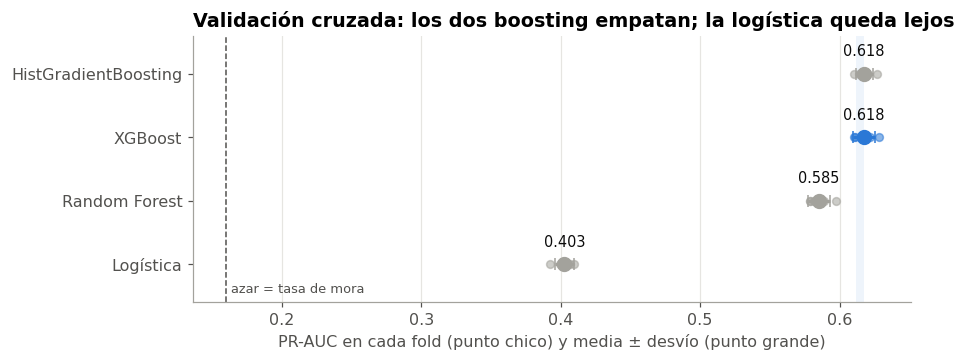

In [18]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
orden = resumen_cv.index[::-1]
for i, n in enumerate(orden):
    vals = cv.loc[cv["modelo"] == n, "PR-AUC"]
    color = AZUL if n == elegido else GRIS
    ax.scatter(vals, [i] * len(vals), color=color, s=26, alpha=0.55, zorder=3)
    ax.errorbar(vals.mean(), i, xerr=vals.std(), fmt="o", color=color, ms=9, capsize=4, lw=2, zorder=4)
    ax.text(vals.mean(), i + 0.28, f"{vals.mean():.3f}", ha="center", fontsize=9.5, color=TINTA)
ax.axvspan(corte, resumen_cv["PR-AUC mean"].max(), color=AZUL, alpha=0.08, lw=0)
ax.axvline(y_dev.mean(), color=TINTA2, ls="--", lw=1)
ax.text(y_dev.mean() + 0.004, -0.45, "azar = tasa de mora", fontsize=8.5, color=TINTA2)
ax.set_yticks(range(len(orden)), orden); ax.set_ylim(-0.6, len(orden) - 0.4)
ax.set_xlabel("PR-AUC en cada fold (punto chico) y media ± desvío (punto grande)")
ax.set_title("Validación cruzada: los dos boosting empatan; la logística queda lejos")
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "f03_validacion_cruzada.png")

## 4.4 Hiperparámetros

Búsqueda aleatoria de 15 combinaciones con validación cruzada de 3 folds. Se usa solo si mejora la configuración por defecto.

In [19]:
ESPACIOS = {
    "XGBoost": {"n_estimators": [300, 500, 800], "max_depth": [3, 4, 5, 6, 8], "learning_rate": [0.02, 0.03, 0.05, 0.1],
                "min_child_weight": [1, 5, 10, 20], "subsample": [0.7, 0.8, 1.0], "colsample_bytree": [0.6, 0.8, 1.0],
                "reg_lambda": [1, 5, 10]},
    "HistGradientBoosting": {"max_iter": [200, 400, 800], "learning_rate": [0.03, 0.05, 0.1], "max_leaf_nodes": [15, 31, 63],
                             "min_samples_leaf": [20, 50, 100], "l2_regularization": [0, 1, 5]},
    "Random Forest": {"m__max_features": ["sqrt", 0.3, 0.5], "m__min_samples_leaf": [1, 3, 5, 10]},
    "Logística": {"m__C": [0.01, 0.1, 1, 10]},
}
t0 = time.time()
busqueda = RandomizedSearchCV(crear_modelo(elegido), ESPACIOS[elegido], n_iter=15 if elegido in ("XGBoost", "HistGradientBoosting") else 4,
                              scoring="average_precision", cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                              random_state=RANDOM_STATE, n_jobs=1)
busqueda.fit(X_para(elegido, X_dev, X_dev_cat), y_dev)
print(f"Búsqueda: {time.time() - t0:.0f} s")
print(f"Mejor PR-AUC (CV 3 folds): {busqueda.best_score_:.4f}")
print("Mejores parámetros:", busqueda.best_params_)

base_score = pd.Series(busqueda.cv_results_["mean_test_score"]).max()
defecto = []
for i_tr, i_va in StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE).split(X_dev, y_dev):
    Xe = X_para(elegido, X_dev, X_dev_cat)
    m = crear_modelo(elegido).fit(Xe.iloc[i_tr], y_dev[i_tr])
    defecto.append(average_precision_score(y_dev[i_va], m.predict_proba(Xe.iloc[i_va])[:, 1]))
print(f"Configuración por defecto (CV 3 folds): {np.mean(defecto):.4f}")
PARAMS = {k.replace("m__", ""): v for k, v in busqueda.best_params_.items()} if busqueda.best_score_ > np.mean(defecto) else {}
print("-> Se usan los parámetros", "ajustados" if PARAMS else "por defecto")

Búsqueda: 117 s
Mejor PR-AUC (CV 3 folds): 0.6152
Mejores parámetros: {'subsample': 0.8, 'reg_lambda': 1, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


Configuración por defecto (CV 3 folds): 0.6159
-> Se usan los parámetros por defecto


La búsqueda no mejoró la configuración por defecto (0,615 contra 0,616): el límite parece estar en los datos y no en el ajuste.

## 4.5 Calibración

Como la regla compara la probabilidad con un umbral, necesitamos que sea confiable: si el modelo dice 20%, alrededor del 20% de esos casos tiene que entrar en mora. Lo verificamos con las predicciones fuera de muestra de la validación cruzada.

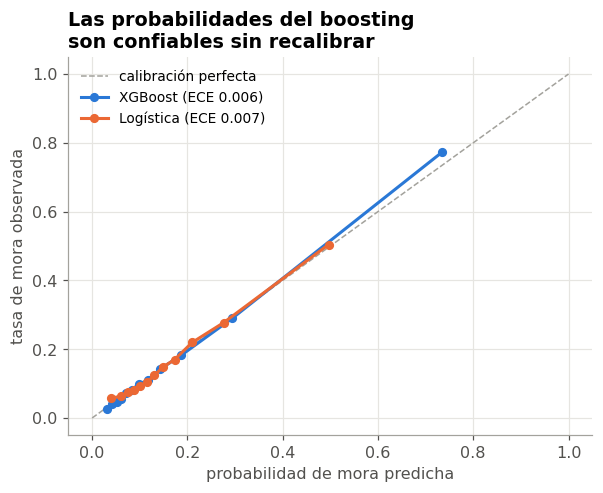

ECE XGBoost: 0.0059


In [20]:
def ece(y, p, bins=10):
    """Error de calibración esperado: distancia promedio entre lo predicho y lo observado."""
    cortes = np.quantile(p, np.linspace(0, 1, bins + 1))
    idx = np.clip(np.searchsorted(cortes, p, side="right") - 1, 0, bins - 1)
    return sum(abs(p[idx == b].mean() - y[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any())


fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.plot([0, 1], [0, 1], ls="--", color=GRIS, lw=1, label="calibración perfecta")
for n, color in [(elegido, AZUL), ("Logística", NARANJA)]:
    fr, mp = calibration_curve(y_dev, oof[n], n_bins=12, strategy="quantile")
    ax.plot(mp, fr, marker="o", ms=5, color=color, label=f"{n} (ECE {ece(y_dev, oof[n]):.3f})")
ax.set_xlabel("probabilidad de mora predicha"); ax.set_ylabel("tasa de mora observada")
ax.set_title("Las probabilidades del boosting\nson confiables sin recalibrar")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
guardar(fig, "f04_calibracion.png")
print(f"ECE {elegido}: {ece(y_dev, oof[elegido]):.4f}")

## 4.6 Modelo final

Entrenamos el modelo elegido con todo desarrollo y 5 semillas, y usamos la de PR-AUC mediano. Acá se usa el test por primera vez.

In [21]:
Xd, Xt = X_para(elegido, X_dev, X_dev_cat), X_para(elegido, X_test, X_test_cat)
semillas = []
for s in SEMILLAS:
    m = crear_modelo(elegido, semilla=s, **PARAMS).fit(Xd, y_dev)
    p = m.predict_proba(Xt)[:, 1]
    semillas.append({"semilla": s, "modelo": m, "p": p, "PR-AUC": average_precision_score(y_test, p),
                     "ROC-AUC": roc_auc_score(y_test, p)})
pr_sem = pd.Series([s["PR-AUC"] for s in semillas])
i_med = pr_sem.sort_values().index[len(pr_sem) // 2]
modelo, p_test = semillas[i_med]["modelo"], semillas[i_med]["p"]
print(f"PR-AUC test en 5 semillas: {pr_sem.mean():.4f} ± {pr_sem.std():.4f}")
print(f"ROC-AUC test en 5 semillas: {np.mean([s['ROC-AUC'] for s in semillas]):.4f} ± {np.std([s['ROC-AUC'] for s in semillas], ddof=1):.4f}")
print(f"Semilla mediana: {semillas[i_med]['semilla']}")

PR-AUC test en 5 semillas: 0.6208 ± 0.0004
ROC-AUC test en 5 semillas: 0.8135 ± 0.0003
Semilla mediana: 2


El desvío entre semillas (0,0004) es despreciable frente a las diferencias entre algoritmos.

---
# 5. Evaluación

## 5.1 Contra qué comparamos

Tres políticas sin machine learning:

1. Aprobar todo.
2. Una regla típica de analista: rechazar si LTV > 80 y deuda/ingreso > 45.
3. La mejor regla posible con LTV y deuda/ingreso: probamos 143 combinaciones de cortes sobre desarrollo y elegimos la de mejor resultado.

In [22]:
def regla(df, ltv, dti, modo):
    a = df["LTV"].to_numpy() > ltv
    b = df["dtir1"].fillna(-1).to_numpy() > dti      # sin dato de DTI: no dispara la regla
    return (a & b) if modo == "y" else (a | b)


grilla = []
for ltv_c in [60, 65, 70, 75, 80, 85, 90, 95, 100, 1e9]:
    for dti_c in [30, 35, 40, 45, 50, 55, 60, 1e9]:
        for modo in ["y", "o"]:
            if ltv_c == 1e9 and dti_c == 1e9:
                continue
            r = resultado(y_dev, regla(dev, ltv_c, dti_c, modo), monto_dev, lgd_dev)
            grilla.append({"LTV >": ltv_c, "DTI >": dti_c, "modo": modo, **r})
grilla = pd.DataFrame(grilla).drop_duplicates(subset=["% rechazado", "resultado neto"])
mejor_regla = grilla.sort_values("resultado neto", ascending=False).iloc[0]


def describir_regla(f):
    partes = []
    if f["LTV >"] < 1e9: partes.append(f"LTV > {f['LTV >']:.0f}")
    if f["DTI >"] < 1e9: partes.append(f"DTI > {f['DTI >']:.0f}")
    return "rechazar si " + (f" {f['modo']} ".join(partes))


TOPE = 20.0   # % máximo de rechazo fijado en la sección 1.3
mejor_regla_tope = grilla[grilla["% rechazado"] <= TOPE].sort_values("resultado neto", ascending=False).iloc[0]
TXT_MEJOR_REGLA = describir_regla(mejor_regla)
TXT_MEJOR_REGLA_TOPE = describir_regla(mejor_regla_tope)
print(f"Reglas evaluadas: {len(grilla)}")
print(f"Mejor regla en desarrollo:                  {TXT_MEJOR_REGLA}  (rechaza {mejor_regla['% rechazado']:.1f}%)")
print(f"Mejor regla que rechaza como máximo {TOPE:.0f}%: {TXT_MEJOR_REGLA_TOPE}  (rechaza {mejor_regla_tope['% rechazado']:.1f}%)")

Reglas evaluadas: 143
Mejor regla en desarrollo:                  rechazar si LTV > 85 o DTI > 50  (rechaza 30.5%)
Mejor regla que rechaza como máximo 20%: rechazar si LTV > 95 o DTI > 50  (rechaza 15.2%)


### Cómo se aplica el tope de 20%

Las solicitudes llegan de a una, así que el tope no puede ser una cuota que se agota en algún momento del año. Lo convertimos en un **corte fijo**: con las predicciones fuera de muestra de desarrollo calculamos la pérdida esperada de cada solicitud, `(p × LGD − (1 − p) × m) × monto`, y buscamos el valor que deja por encima al 20%. En operación se rechaza toda solicitud que supere ese corte.

Si en algún mes el rechazo se aleja mucho del 20%, es una señal de que cambiaron los clientes y hay que revisar el modelo. Para comparar en igualdad de condiciones, la regla también se limita al 20%.

In [23]:
def perdida_esperada(p, lgd_, monto, margen=MARGEN):
    return (p * lgd_ - (1 - p) * margen) * monto


def corte_tope(p_dev, lgd_dev_, monto_dev_, tope=TOPE, margen=MARGEN):
    """Corte en USD de pérdida esperada que deja por encima al tope% de las solicitudes de desarrollo."""
    return max(0.0, float(np.quantile(perdida_esperada(p_dev, lgd_dev_, monto_dev_, margen), 1 - tope / 100)))


def rechazo_con_corte(p, lgd_, monto, corte, margen=MARGEN):
    return perdida_esperada(p, lgd_, monto, margen) > corte


CORTE_USD = corte_tope(oof[elegido], lgd_dev, monto_dev)
print(f"Corte fijo: rechazar si la pérdida esperada de la solicitud supera {plata(CORTE_USD)}")
print(f"(sin tope, la regla económica pura rechazaría el {np.mean(perdida_esperada(oof[elegido], lgd_dev, monto_dev) > 0):.1%} de desarrollo)")

Corte fijo: rechazar si la pérdida esperada de la solicitud supera USD 1.204
(sin tope, la regla económica pura rechazaría el 23.7% de desarrollo)


## 5.2 Resultados en test

In [24]:
politicas = {
    "Aprobar todo": np.zeros(len(test), dtype=bool),
    "Regla propuesta (LTV>80 y DTI>45)": regla(test, 80, 45, "y"),
    f"Mejor regla ({TXT_MEJOR_REGLA.replace('rechazar si ', '')})": regla(test, mejor_regla["LTV >"], mejor_regla["DTI >"], mejor_regla["modo"]),
    f"Modelo {elegido}, regla económica pura": rechazo_economico(p_test, lgd_test),
    f"Mejor regla con tope {TOPE:.0f}% ({TXT_MEJOR_REGLA_TOPE.replace('rechazar si ', '')})": regla(test, mejor_regla_tope["LTV >"], mejor_regla_tope["DTI >"], mejor_regla_tope["modo"]),
    f"Modelo {elegido} con tope {TOPE:.0f}% (recomendada)": rechazo_con_corte(p_test, lgd_test, monto_test, CORTE_USD),
}
comparacion = pd.DataFrame({k: resultado(y_test, r, monto_test, lgd_test) for k, r in politicas.items()}).T
comparacion["recall (moras detectadas)"] = comparacion["moras rechazadas"] / y_test.sum() * 100
comparacion["precisión del rechazo"] = comparacion["moras rechazadas"] / (comparacion["moras rechazadas"] + comparacion["buenos rechazados"]).replace(0, np.nan) * 100
tabla(comparacion.round(2), "t06_comparacion_politicas_test.csv", index=True)

vista = comparacion[["% rechazado", "recall (moras detectadas)", "precisión del rechazo", "pérdida crediticia", "margen perdido", "resultado neto"]].copy()
for c in ["pérdida crediticia", "margen perdido", "resultado neto"]:
    vista[c] = vista[c].map(plata)
vista.round(1)

,% rechazado,recall (moras detectadas),precisión del rechazo,pérdida crediticia,margen perdido,resultado neto
Aprobar todo,0.0000,0.0000,NaN,USD 230.291.800,USD 0,USD 51.250.460
Regla propuesta (LTV>80 y DTI>45),9.8000,16.6000,26.9000,USD 170.459.100,USD 23.915.625,USD 87.167.535
Mejor regla (LTV > 85 o DTI > 50),30.5000,46.7000,24.5000,USD 69.528.700,USD 78.495.975,USD 133.517.585
"Modelo XGBoost, regla económica pura",23.1000,58.8000,40.7000,USD 64.016.125,USD 38.372.850,USD 179.153.285
Mejor regla con tope 20% (LTV > 95 o DTI > 50),15.2000,31.3000,32.9000,USD 126.197.200,USD 32.404.440,USD 122.940.620
Modelo XGBoost con tope 20% (recomendada),19.4000,54.6000,44.9000,USD 71.271.525,USD 31.325.565,USD 178.945.170


In [25]:
NOMBRES = list(politicas)
REGLA_P, MEJOR_R, MOD, MEJOR_R20, MOD20 = NOMBRES[1:]
perd_todo = comparacion.loc["Aprobar todo", "pérdida crediticia"]
for n in NOMBRES[1:]:
    print(f"{n:<45} pérdida crediticia {plata(comparacion.loc[n, 'pérdida crediticia']):>18}"
          f"  (−{(1 - comparacion.loc[n, 'pérdida crediticia'] / perd_todo):.1%} vs aprobar todo)"
          f"   resultado {plata(comparacion.loc[n, 'resultado neto'])}")

Regla propuesta (LTV>80 y DTI>45)             pérdida crediticia    USD 170.459.100  (−26.0% vs aprobar todo)   resultado USD 87.167.535
Mejor regla (LTV > 85 o DTI > 50)             pérdida crediticia     USD 69.528.700  (−69.8% vs aprobar todo)   resultado USD 133.517.585
Modelo XGBoost, regla económica pura          pérdida crediticia     USD 64.016.125  (−72.2% vs aprobar todo)   resultado USD 179.153.285
Mejor regla con tope 20% (LTV > 95 o DTI > 50) pérdida crediticia    USD 126.197.200  (−45.2% vs aprobar todo)   resultado USD 122.940.620
Modelo XGBoost con tope 20% (recomendada)     pérdida crediticia     USD 71.271.525  (−69.1% vs aprobar todo)   resultado USD 178.945.170


Para ver si el corte fijo mantiene el 20%, repartimos el test en 12 "meses" al azar (el dataset no tiene fechas):

In [26]:
mes = np.random.default_rng(RANDOM_STATE).integers(0, 12, len(y_test))
rech_mes = pd.Series([politicas[MOD20][mes == k].mean() * 100 for k in range(12)], index=[f"mes {k + 1}" for k in range(12)])
print("Rechazo por mes (%):", " · ".join(f"{v:.1f}" for v in rech_mes))
print(f"Mínimo {rech_mes.min():.1f}% · máximo {rech_mes.max():.1f}%")

Rechazo por mes (%): 19.0 · 19.5 · 20.2 · 19.8 · 19.8 · 18.7 · 20.0 · 18.8 · 18.2 · 19.4 · 20.1 · 19.6
Mínimo 18.2% · máximo 20.2%


## 5.3 A igual tasa de rechazo

Cualquier política pierde menos si rechaza más, así que también comparamos rechazando la misma cantidad de solicitudes que cada regla.

In [27]:
def rechazo_por_cuota(p, pct, lgd_=None, monto=None):
    """Rechaza el pct% de solicitudes con mayor pérdida esperada en dólares (el mismo orden que usa la política recomendada)."""
    lgd_ = lgd_test if lgd_ is None else lgd_
    monto = monto_test if monto is None else monto
    rechazar = np.zeros(len(p), dtype=bool)
    k = int(round(len(p) * pct / 100))
    if k > 0:
        rechazar[np.argsort(-((p * lgd_ - (1 - p) * MARGEN) * monto))[:k]] = True
    return rechazar


igual = []
for n in [REGLA_P, MEJOR_R]:
    pct = comparacion.loc[n, "% rechazado"]
    r_mod = resultado(y_test, rechazo_por_cuota(p_test, pct), monto_test, lgd_test)
    igual.append({"rechazando el mismo % que": n, "% rechazado": pct,
                  "pérdida con la regla": comparacion.loc[n, "pérdida crediticia"],
                  "pérdida con el modelo": r_mod["pérdida crediticia"],
                  "moras detectadas regla": int(comparacion.loc[n, "moras rechazadas"]),
                  "moras detectadas modelo": r_mod["moras rechazadas"]})
igual = pd.DataFrame(igual)
igual["pérdida evitada adicional"] = igual["pérdida con la regla"] - igual["pérdida con el modelo"]
igual["% menos pérdida"] = (1 - igual["pérdida con el modelo"] / igual["pérdida con la regla"]) * 100
tabla(igual.round(2), "t07_igual_tasa_rechazo.csv")
igual.round(1)

,rechazando el mismo % que,% rechazado,pérdida con la regla,pérdida con el modelo,moras detectadas regla,moras detectadas modelo,pérdida evitada adicional,% menos pérdida
0,Regla propuesta (LTV>80 y DTI>45),9.8000,"170,459,100.0000","99,322,075.0000",883,2072,"71,137,025.0000",41.7000
1,Mejor regla (LTV > 85 o DTI > 50),30.5000,"69,528,700.0000","53,832,700.0000",2490,3544,"15,696,000.0000",22.6000


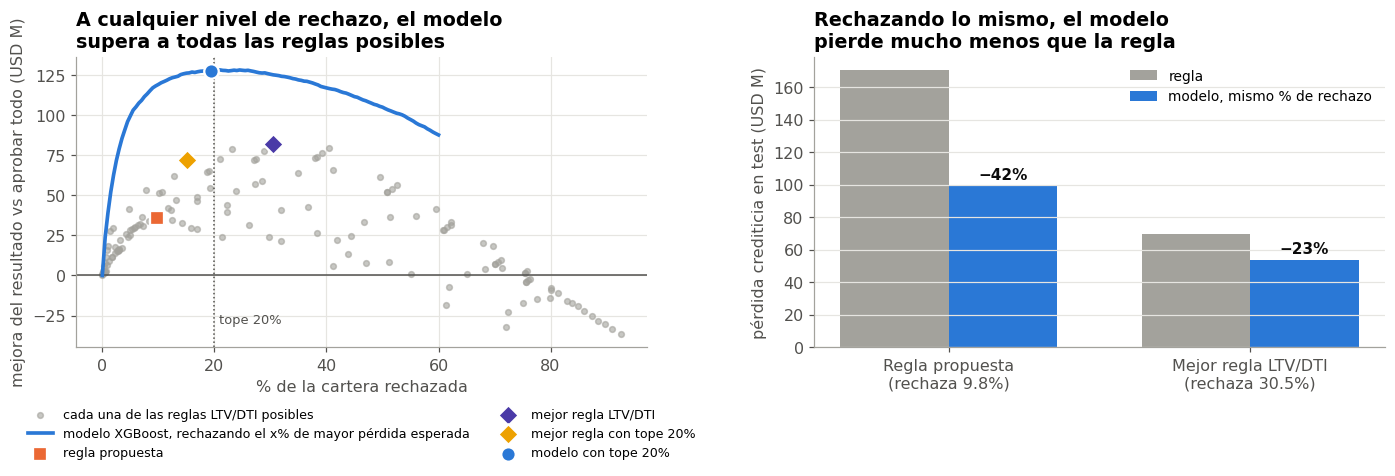

In [28]:
# Curva de todas las políticas posibles: % rechazado vs resultado neto
cuotas = np.r_[0, np.linspace(0.5, 60, 120)]
curva_mod = pd.DataFrame([{"% rechazado": c, **resultado(y_test, rechazo_por_cuota(p_test, c), monto_test, lgd_test)} for c in cuotas])
grilla_test = pd.DataFrame([{**resultado(y_test, regla(test, f["LTV >"], f["DTI >"], f["modo"]), monto_test, lgd_test)}
                            for _, f in grilla.iterrows()])
res_todo = comparacion.loc["Aprobar todo", "resultado neto"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.scatter(grilla_test["% rechazado"], (grilla_test["resultado neto"] - res_todo) / 1e6, s=14, color=GRIS, alpha=0.6,
           label="cada una de las reglas LTV/DTI posibles", zorder=2)
ax.plot(curva_mod["% rechazado"], (curva_mod["resultado neto"] - res_todo) / 1e6, color=AZUL, lw=2.4,
        label=f"modelo {elegido}, rechazando el x% de mayor pérdida esperada", zorder=3)
for n, color, mk, etiqueta in [(REGLA_P, NARANJA, "s", "regla propuesta"), (MEJOR_R, VIOLETA, "D", "mejor regla LTV/DTI"),
                               (MEJOR_R20, AMARILLO, "D", "mejor regla con tope 20%"), (MOD20, AZUL, "o", "modelo con tope 20%")]:
    ax.scatter(comparacion.loc[n, "% rechazado"], (comparacion.loc[n, "resultado neto"] - res_todo) / 1e6,
               s=90, color=color, marker=mk, edgecolor="white", lw=1.5, zorder=5, label=etiqueta)
ax.axvline(TOPE, color=TINTA2, ls=":", lw=1)
ax.text(TOPE + 0.8, -30, "tope 20%", fontsize=8.5, color=TINTA2)
ax.axhline(0, color=TINTA2, lw=1)
ax.set_xlabel("% de la cartera rechazada"); ax.set_ylabel("mejora del resultado vs aprobar todo (USD M)")
ax.set_title("A cualquier nivel de rechazo, el modelo\nsupera a todas las reglas posibles")
ax.legend(fontsize=8.3, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)

ax = axes[1]
w = 0.36
x = np.arange(len(igual))
ax.bar(x - w / 2, igual["pérdida con la regla"] / 1e6, w, color=GRIS, label="regla")
ax.bar(x + w / 2, igual["pérdida con el modelo"] / 1e6, w, color=AZUL, label="modelo, mismo % de rechazo")
for i, f in igual.iterrows():
    ax.text(i + w / 2, f["pérdida con el modelo"] / 1e6 + 4, f"−{f['% menos pérdida']:.0f}%", ha="center",
            fontsize=10, color=TINTA, fontweight="bold")
ax.set_xticks(x, [f"Regla propuesta\n(rechaza {igual.loc[0, '% rechazado']:.1f}%)",
                  f"Mejor regla LTV/DTI\n(rechaza {igual.loc[1, '% rechazado']:.1f}%)"])
ax.set_ylabel("pérdida crediticia en test (USD M)")
ax.set_title("Rechazando lo mismo, el modelo\npierde mucho menos que la regla")
ax.legend(loc="upper right", fontsize=9); ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "f05_modelo_vs_reglas.png")

## 5.4 Intervalos bootstrap

Remuestreamos el test 1.000 veces, con los mismos remuestreos para todas las políticas. Si el intervalo de 95% de la diferencia no incluye el cero, la ventaja no es casualidad.

In [29]:
rng = np.random.default_rng(RANDOM_STATE)
B = 1000
boot = {"PR-AUC": [], "dif vs regla propuesta": [], "dif vs mejor regla": [], "dif con tope 20%": []}
# contribución de cada solicitud al resultado neto: 0 si se rechaza, +margen si paga, −pérdida si entra en mora
contrib = {n: np.where(politicas[n], 0.0, np.where(y_test == 1, -lgd_test * monto_test, MARGEN * monto_test)) for n in NOMBRES}
for _ in range(B):
    i = rng.integers(0, len(y_test), len(y_test))
    boot["PR-AUC"].append(average_precision_score(y_test[i], p_test[i]))
    boot["dif vs regla propuesta"].append(contrib[MOD20][i].sum() - contrib[REGLA_P][i].sum())
    boot["dif vs mejor regla"].append(contrib[MOD][i].sum() - contrib[MEJOR_R][i].sum())
    boot["dif con tope 20%"].append(contrib[MOD20][i].sum() - contrib[MEJOR_R20][i].sum())
ic = pd.DataFrame({k: {"estimación": np.mean(v), "IC 95% inferior": np.percentile(v, 2.5),
                       "IC 95% superior": np.percentile(v, 97.5)} for k, v in boot.items()}).T
tabla(ic, "t08_bootstrap.csv", index=True)
ic

,estimación,IC 95% inferior,IC 95% superior
PR-AUC,0.6210,0.6097,0.6330
dif vs regla propuesta,"91,809,204.1800","85,695,124.8750","97,960,574.7500"
dif vs mejor regla,"45,615,479.0250","41,056,422.0000","49,865,884.8750"
dif con tope 20%,"55,907,430.8900","50,970,822.7500","60,782,749.3750"


**Resumen de la evaluación**

- La regla de analista (LTV > 80 y DTI > 45) es débil: rechaza el 9,8% y su precisión (27%) apenas supera la tasa de mora.
- La mejor regla (LTV > 85 o DTI > 50) reduce bastante la pérdida, pero rechaza el 30,5%.
- Rechazando lo mismo, el modelo pierde 23% menos que la mejor regla y 42% menos que la de analista.
- Con el tope de 20%, el modelo supera a la mejor regla con el mismo tope y el intervalo bootstrap queda lejos de cero.
- Las cifras en dólares son una simulación con margen de 3% y recupero de 70%.

## 5.5 Métricas de clasificación

Para los cuatro algoritmos, cada uno con su propio corte fijo.

In [30]:
metricas = []
for nombre in MODELOS:
    if nombre == elegido:
        p = p_test
    else:
        m = crear_modelo(nombre).fit(X_para(nombre, X_dev, X_dev_cat), y_dev)
        p = m.predict_proba(X_para(nombre, X_test, X_test_cat))[:, 1]
    # cada modelo con su propio corte fijo, calibrado con sus predicciones fuera de muestra
    rech = rechazo_con_corte(p, lgd_test, monto_test, corte_tope(oof[nombre], lgd_dev, monto_dev))
    r = resultado(y_test, rech, monto_test, lgd_test)
    metricas.append({"modelo": nombre, "PR-AUC": average_precision_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, p),
                     "Brier": brier_score_loss(y_test, p), "accuracy": accuracy_score(y_test, rech),
                     "precisión": precision_score(y_test, rech), "recall": recall_score(y_test, rech),
                     "F1": f1_score(y_test, rech), "% rechazado": rech.mean() * 100,
                     "resultado neto (USD M)": r["resultado neto"] / 1e6})
metricas = tabla(pd.DataFrame(metricas).set_index("modelo"), "t09_metricas_test.csv", index=True)
metricas.round(3)

,PR-AUC,ROC-AUC,Brier,accuracy,precisión,recall,F1,% rechazado,resultado neto (USD M)
modelo,,,,,,,,,
Logística,0.4000,0.7160,0.1180,0.7750,0.3330,0.4060,0.3660,19.4660,141.2330
Random Forest,0.5930,0.8020,0.0960,0.8110,0.4250,0.5200,0.4680,19.5410,175.0030
HistGradientBoosting,0.6210,0.8140,0.0910,0.8200,0.4480,0.5450,0.4920,19.4660,179.3000
XGBoost,0.6210,0.8130,0.0920,0.8200,0.4490,0.5460,0.4930,19.4210,178.9450


- Los dos boosting también empatan en test (PR-AUC 0,621). No cambiamos la elección, porque eso sería elegir mirando el test.
- La accuracy del modelo (82%) es menor que la de predecir siempre "no mora" (84%): rechaza a propósito a algunos buenos pagadores porque evitar una mora vale más que el margen perdido.
- Recall 55% y precisión 45%: de cada 100 rechazados, 45 habrían entrado en mora, casi el triple de la tasa base.

In [31]:
# Matriz de confusión del modelo elegido, en lenguaje de negocio
rech = politicas[MOD20]
mc = pd.DataFrame({"pagó": [int((~rech & (y_test == 0)).sum()), int((rech & (y_test == 0)).sum())],
                   "entró en mora": [int((~rech & (y_test == 1)).sum()), int((rech & (y_test == 1)).sum())]},
                  index=["el modelo aprueba", "el modelo rechaza"])
tabla(mc, "t10_matriz_confusion.csv", index=True)
mc

,pagó,entró en mora
el modelo aprueba,24441,2420
el modelo rechaza,3567,2907


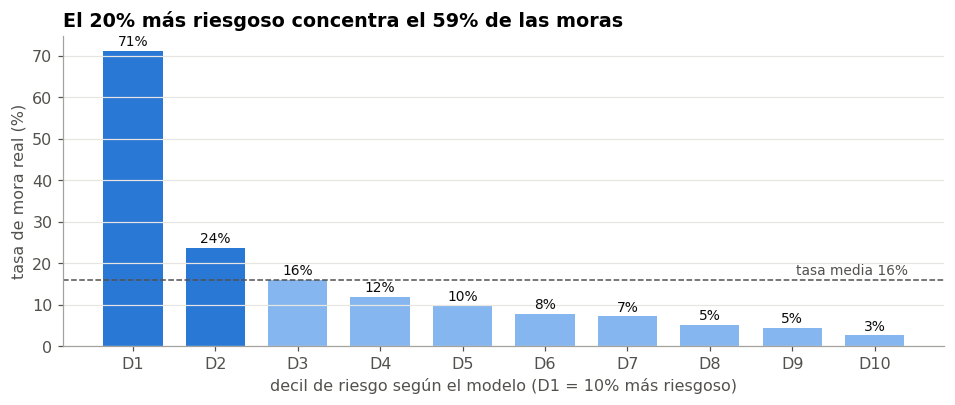

In [32]:
# Deciles de riesgo: cuánta mora concentra cada décimo de la cartera
dec = pd.qcut(pd.Series(p_test).rank(method="first"), 10, labels=range(10, 0, -1))
deciles = pd.DataFrame({"y": y_test, "dec": dec.astype(int), "p": p_test}).groupby("dec").agg(
    solicitudes=("y", "size"), moras=("y", "sum"), tasa=("y", "mean"), p_media=("p", "mean")).sort_index()
deciles["lift"] = deciles["tasa"] / y_test.mean()
deciles["% moras acumulado"] = deciles["moras"].cumsum() / y_test.sum() * 100
tabla(deciles.round(4), "t11_deciles.csv", index=True)

fig, ax = plt.subplots(figsize=(8.8, 3.8))
ax.bar(deciles.index, deciles["tasa"] * 100, color=[AZUL if d <= 2 else "#86b6ef" for d in deciles.index], width=0.72)
ax.axhline(y_test.mean() * 100, color=TINTA2, ls="--", lw=1)
ax.text(10.4, y_test.mean() * 100 + 1.2, f"tasa media {y_test.mean():.0%}", ha="right", fontsize=9, color=TINTA2)
for d, f in deciles.iterrows():
    ax.text(d, f["tasa"] * 100 + 1.2, f"{f['tasa']:.0%}", ha="center", fontsize=9, color=TINTA)
ax.set_xticks(deciles.index, [f"D{d}" for d in deciles.index])
ax.set_xlabel("decil de riesgo según el modelo (D1 = 10% más riesgoso)"); ax.set_ylabel("tasa de mora real (%)")
ax.set_title(f"El 20% más riesgoso concentra el {deciles.loc[2, '% moras acumulado']:.0f}% de las moras")
ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "f06_deciles.png")

El 10% más riesgoso tiene 71% de mora y los dos primeros deciles concentran el 59% de las moras; el decil más seguro tiene 3%. En cada decil la probabilidad predicha coincide con la tasa observada.

---
# 6. Qué aporta cada variable

## 6.1 Ablaciones

Reentrenamos el modelo sacando cada grupo de variables (una por hipótesis) o volviendo a agregar las que excluimos. Todas las variantes rechazan el mismo 20%, así que la diferencia se debe solo a las variables.

Primero, la tasa de mora según las dos variables excluidas:

In [33]:
for col in DESCARTADAS:
    t = datos.groupby(col)[TARGET].agg(["mean", "size"]).rename(columns={"mean": "tasa de mora", "size": "solicitudes"})
    print(t.round(3), "\n")


def ablacion(sin=(), con=()):
    feats = [c for c in FEATURES if c not in sin] + list(con)
    Xd_ = X_dev_cat_full[feats]
    Xt_ = X_test_cat_full[feats]
    ps = []
    for s in SEMILLAS[:3]:
        m = crear_modelo(elegido, semilla=s, **PARAMS).fit(Xd_, y_dev)
        ps.append(m.predict_proba(Xt_)[:, 1])
    p = np.mean(ps, axis=0)
    pr = [average_precision_score(y_test, q) for q in ps]
    # todas las variantes rechazan el mismo 20% de mayor pérdida esperada: compara solo las variables
    r = resultado(y_test, rechazo_por_cuota(p, TOPE), monto_test, lgd_test)
    return {"PR-AUC": np.mean(pr), "PR-AUC desvío": np.std(pr, ddof=1), "resultado neto (USD M)": r["resultado neto"] / 1e6,
            "% rechazado": r["% rechazado"]}


# Para las ablaciones agregamos las columnas descartadas y los atributos protegidos como
# columnas disponibles (cada una se usa solo en su fila)
_cats_full = CATEGORICAS + SENSIBLES + DESCARTADAS
X_dev_cat_full = dev[FEATURES + SENSIBLES + DESCARTADAS].copy()
X_test_cat_full = test[FEATURES + SENSIBLES + DESCARTADAS].copy()
for c in _cats_full:
    X_dev_cat_full[c] = X_dev_cat_full[c].astype("category")
    X_test_cat_full[c] = pd.Categorical(X_test_cat_full[c], categories=X_dev_cat_full[c].cat.categories)

t0 = time.time()
ablaciones = {
    "Modelo final (referencia)": ablacion(),
    "Con Credit_Worthiness (descartada)": ablacion(con=["Credit_Worthiness"]),
    "Con submission_of_application (descartada)": ablacion(con=["submission_of_application"]),
    "Con las dos descartadas": ablacion(con=DESCARTADAS),
    "H1 · sin capacidad de pago (dtir1, income, lti, ingreso_cero)": ablacion(sin=["dtir1", "income", "lti", "ingreso_cero"]),
    "H2 · sin garantía (LTV, property_value)": ablacion(sin=["LTV", "property_value"]),
    "H3 · sin estructura del producto": ablacion(sin=["lump_sum_payment", "Neg_ammortization", "interest_only", "business_or_commercial", "loan_type", "term"]),
    "H4 · sin Credit_Score": ablacion(sin=["Credit_Score"]),
    "Con Gender y age (atributos protegidos)": ablacion(con=SENSIBLES),
}
abl = pd.DataFrame(ablaciones).T
ref = abl.iloc[0]
abl["Δ PR-AUC (puntos)"] = (abl["PR-AUC"] - ref["PR-AUC"]) * 100
abl["Δ resultado (USD M)"] = abl["resultado neto (USD M)"] - ref["resultado neto (USD M)"]
tabla(abl.round(4), "t12_ablaciones.csv", index=True)
print(f"Ablaciones: {time.time() - t0:.0f} s")
abl.round(3)

                   tasa de mora  solicitudes
Credit_Worthiness                           
l1                       0.1580       127874
l2                       0.2100         5463 

                           tasa de mora  solicitudes
submission_of_application                           
not_inst                         0.0980        48141
to_inst                          0.1950        85196 



Ablaciones: 90 s


,PR-AUC,PR-AUC desvío,resultado neto (USD M),% rechazado,Δ PR-AUC (puntos),Δ resultado (USD M)
Modelo final (referencia),0.6210,0.0000,179.7490,20.0000,0.0000,0.0000
Con Credit_Worthiness (descartada),0.6250,0.0010,180.5590,20.0000,0.4250,0.8100
Con submission_of_application (descartada),0.6270,0.0010,183.6560,20.0000,0.6500,3.9070
Con las dos descartadas,0.6320,0.0000,184.7460,20.0000,1.1120,4.9970
"H1 · sin capacidad de pago (dtir1, income, lti, ingreso_cero)",0.4970,0.0000,157.2190,20.0000,-12.3810,-22.5300
"H2 · sin garantía (LTV, property_value)",0.5540,0.0000,165.5500,20.0000,-6.6490,-14.1990
H3 · sin estructura del producto,0.5170,0.0010,162.7060,20.0000,-10.3870,-17.0430
H4 · sin Credit_Score,0.6220,0.0000,179.4100,20.0000,0.0910,-0.3390
Con Gender y age (atributos protegidos),0.6220,0.0010,180.2250,20.0000,0.1360,0.4760


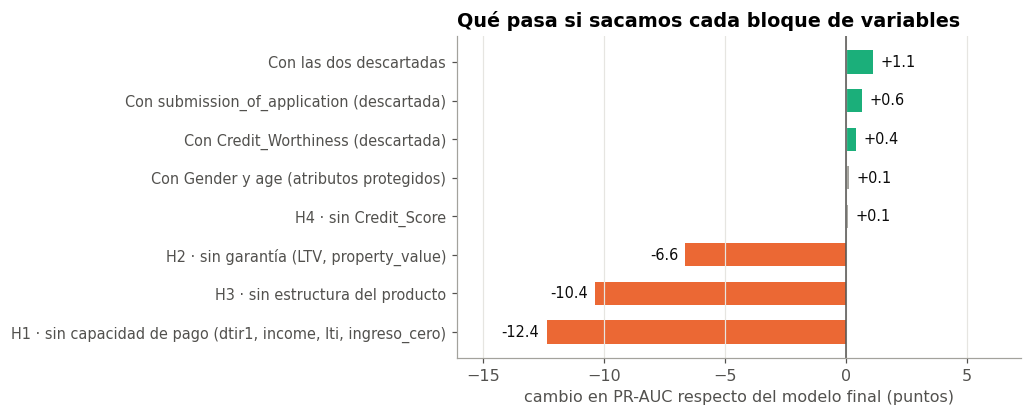

In [34]:
fig, ax = plt.subplots(figsize=(9.5, 3.9))
a = abl.iloc[1:].sort_values("Δ PR-AUC (puntos)")
colores = [NARANJA if v < -1 else (AQUA if v > 0.2 else GRIS) for v in a["Δ PR-AUC (puntos)"]]
ax.barh(range(len(a)), a["Δ PR-AUC (puntos)"], color=colores, height=0.6)
for i, (vv, sd) in enumerate(zip(a["Δ PR-AUC (puntos)"], a["PR-AUC desvío"] * 100)):
    ax.text(vv + (0.3 if vv >= 0 else -0.3), i, f"{vv:+.1f}", va="center", ha="left" if vv >= 0 else "right", fontsize=9.5, color=TINTA)
ax.set_yticks(range(len(a)), a.index, fontsize=9.5)
ax.axvline(0, color=TINTA2, lw=1)
ax.set_xlabel("cambio en PR-AUC respecto del modelo final (puntos)")
ax.set_title("Qué pasa si sacamos cada bloque de variables")
ax.grid(axis="y", visible=False)
lim = max(abs(a["Δ PR-AUC (puntos)"]).max() * 1.3, 2)
ax.set_xlim(-lim, lim * 0.45)
fig.tight_layout()
guardar(fig, "f07_ablaciones.png")

### Lectura

- **`Credit_Worthiness`:** agregarla suma 0,4 puntos de PR-AUC, menos del 1% del resultado. La sacamos porque puede ser la calificación del sistema actual del banco, y el modelo no depende de ella.
- **`submission_of_application`:** suma 0,6 puntos y USD 3,9 M. Las solicitudes `to_inst` tienen el doble de mora que las `not_inst`, pero no sabemos qué significa ese código. La sacamos porque no podríamos explicar un rechazo basado en ella.
- Las dos juntas cuestan 1,1 puntos de PR-AUC, menos del 3% del resultado.

| Hipótesis | ¿Se sostiene? | PR-AUC sin ese bloque |
|---|---|---|
| H1 · capacidad de pago | Sí, es la más importante | −12,4 puntos |
| H2 · garantía | Sí | −6,6 puntos |
| H3 · tipo de producto | Sí | −10,4 puntos |
| H4 · `Credit_Score` | No | +0,1 puntos |

Agregar género y edad no mejora el modelo (+0,1 puntos), así que excluirlos no tiene costo.

## 6.2 Curva de aprendizaje

Entrenamos con fracciones crecientes de desarrollo y medimos sobre una parte fija que el modelo no ve. Si la curva sigue subiendo al final, conseguir más datos ayudaría.

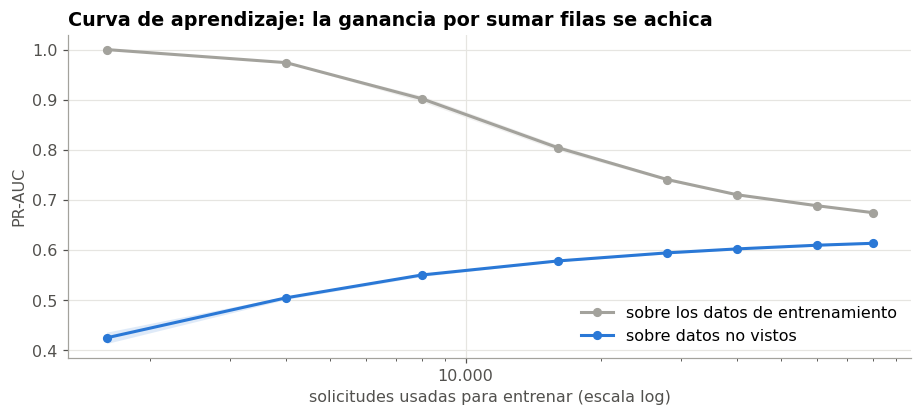

filas
1600    0.4250
4000    0.5048
8000    0.5504
16000   0.5783
28000   0.5945
40000   0.6023
60000   0.6097
80001   0.6135


In [35]:
i_a, i_b = train_test_split(np.arange(len(y_dev)), test_size=0.2, stratify=y_dev, random_state=RANDOM_STATE)
Xa, Xb = X_para(elegido, X_dev, X_dev_cat).iloc[i_a], X_para(elegido, X_dev, X_dev_cat).iloc[i_b]
ya, yb = y_dev[i_a], y_dev[i_b]
curva = []
for frac in [0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0]:
    for s in SEMILLAS[:3]:
        if frac < 1:
            idx, _ = train_test_split(np.arange(len(ya)), train_size=frac, stratify=ya, random_state=s)
        else:
            idx = np.arange(len(ya))
        m = crear_modelo(elegido, semilla=s, **PARAMS).fit(Xa.iloc[idx], ya[idx])
        curva.append({"filas": len(idx), "frac": frac, "PR-AUC validación": average_precision_score(yb, m.predict_proba(Xb)[:, 1]),
                      "PR-AUC entrenamiento": average_precision_score(ya[idx], m.predict_proba(Xa.iloc[idx])[:, 1])})
curva = pd.DataFrame(curva).groupby("filas").agg(["mean", "std"])
tabla(curva.round(4), "t13_curva_aprendizaje.csv", index=True)

fig, ax = plt.subplots(figsize=(8.5, 3.9))
for col, color, lab in [("PR-AUC entrenamiento", GRIS, "sobre los datos de entrenamiento"),
                        ("PR-AUC validación", AZUL, "sobre datos no vistos")]:
    mu, sd = curva[(col, "mean")], curva[(col, "std")]
    ax.plot(curva.index, mu, marker="o", ms=5, color=color, label=lab)
    ax.fill_between(curva.index, mu - sd, mu + sd, color=color, alpha=0.15, lw=0)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.set_xlabel("solicitudes usadas para entrenar (escala log)"); ax.set_ylabel("PR-AUC")
ax.set_title("Curva de aprendizaje: la ganancia por sumar filas se achica")
ax.legend(loc="lower right")
fig.tight_layout()
guardar(fig, "f08_curva_aprendizaje.png")
print(curva[("PR-AUC validación", "mean")].round(4).to_string())

Pasar de 40.000 a 80.000 solicitudes mejora el PR-AUC solo 1 punto (0,602 → 0,614). Más filas no cambiarían mucho; harían falta otras variables, como historial de pagos, antigüedad laboral o datos con fecha.

## 6.3 Efecto del bloque excluido

Entrenamos el mismo modelo con el dataset completo para ver cuánto del resultado vendría solo de reconocer el bloque de 2.3.

In [36]:
completo = agregar_variables(crudo)
dev_c, test_c = train_test_split(completo, test_size=0.25, stratify=completo[TARGET], random_state=RANDOM_STATE)
Xdc = dev_c[FEATURES].copy()
Xtc = test_c[Xdc.columns].copy()
for c in [c for c in Xdc.columns if c in CATEGORICAS]:
    Xdc[c] = Xdc[c].astype("category"); Xtc[c] = pd.Categorical(Xtc[c], categories=Xdc[c].cat.categories)
m_c = crear_modelo("XGBoost", semilla=1).fit(Xdc, dev_c[TARGET])
p_c = m_c.predict_proba(Xtc)[:, 1]
inflado = tabla(pd.DataFrame({
    "con el bloque": {"ROC-AUC": roc_auc_score(test_c[TARGET], p_c), "PR-AUC": average_precision_score(test_c[TARGET], p_c), "tasa de mora": test_c[TARGET].mean()},
    "sin el bloque": {"ROC-AUC": roc_auc_score(y_test, p_test), "PR-AUC": average_precision_score(y_test, p_test), "tasa de mora": y_test.mean()},
}).T.round(4), "t14_efecto_artefacto.csv", index=True)
inflado

,ROC-AUC,PR-AUC,tasa de mora
con el bloque,0.8921,0.8445,0.2464
sin el bloque,0.8130,0.6207,0.1598


Con el bloque, el modelo llega a ROC-AUC 0,89 y PR-AUC 0,84; sin él, a 0,81 y 0,62. Esa diferencia no es capacidad de predecir el riesgo sino de reconocer el bloque.

---
# 7. Interpretación (SHAP)

SHAP reparte cada predicción entre las variables. Lo usamos para ver qué variables pesan más en general y para explicar un rechazo puntual. Los valores están en log-odds y muestran cómo razona el modelo, no relaciones causales.

In [37]:
muestra = X_test_cat.sample(3000, random_state=RANDOM_STATE) if elegido in ("XGBoost", "HistGradientBoosting") else None
if elegido == "XGBoost":
    import xgboost as xgb
    contrib_ = modelo.get_booster().predict(xgb.DMatrix(muestra, enable_categorical=True), pred_contribs=True)
    valores, base = contrib_[:, :-1], contrib_[:, -1]
else:
    explainer = shap.TreeExplainer(modelo)
    valores = explainer.shap_values(muestra)
    base = np.full(len(muestra), explainer.expected_value)
datos_vista = test.loc[muestra.index, FEATURES].copy()
expl = shap.Explanation(values=valores, base_values=base, data=datos_vista.to_numpy(), feature_names=FEATURES)

imp_shap = pd.Series(np.abs(valores).mean(axis=0), index=FEATURES).sort_values(ascending=False)
tabla(imp_shap.rename("|SHAP| medio").to_frame(), "t15_importancia_shap.csv", index=True)
imp_shap.head(12).round(4)

LTV                        0.4594
dtir1                      0.3245
loan_purpose               0.2457
Neg_ammortization          0.1894
loan_type                  0.1846
lti                        0.1669
income                     0.1566
co-applicant_credit_type   0.1337
Region                     0.1184
lump_sum_payment           0.0944
property_value             0.0937
occupancy_type             0.0736
dtype: float32

Arriba aparecen la garantía (LTV), la capacidad de pago (deuda/ingreso, préstamo/ingreso, ingreso) y el tipo de producto (propósito, amortización negativa, tipo de préstamo). `Credit_Score` queda al fondo, igual que en el EDA. Algunas variables (`loan_purpose`, `loan_type`, `co-applicant_credit_type`) tienen códigos sin documentar (p1-p4, type1-type3) que habría que validar con el negocio.

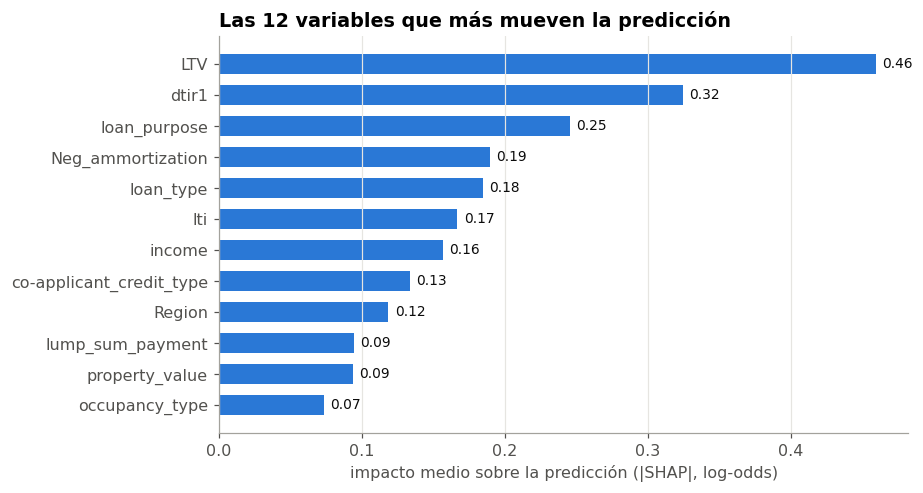

In [38]:
top = imp_shap.head(12)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh(range(len(top))[::-1], top.values, color=AZUL, height=0.65)
ax.set_yticks(range(len(top))[::-1], top.index)
for i, vv in zip(range(len(top))[::-1], top.values):
    ax.text(vv + top.max() * 0.01, i, f"{vv:.2f}", va="center", fontsize=9, color=TINTA)
ax.set_xlabel("impacto medio sobre la predicción (|SHAP|, log-odds)")
ax.set_title("Las 12 variables que más mueven la predicción")
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "f09_shap_importancia.png")

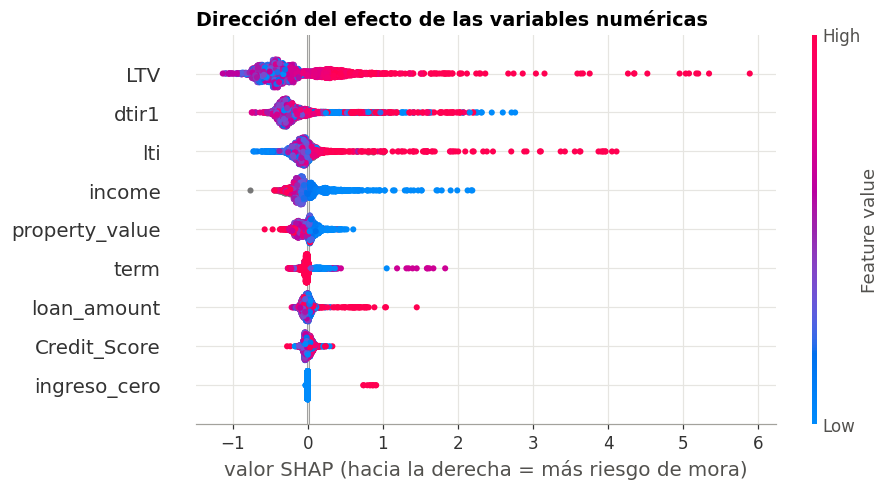

In [39]:
num_top = [c for c in imp_shap.index if c in NUMERICAS][:10]
cols_idx = [FEATURES.index(c) for c in num_top]
expl_num = shap.Explanation(values=valores[:, cols_idx], base_values=base,
                            data=datos_vista[num_top].astype(float).to_numpy(), feature_names=num_top)
plt.figure()
shap.plots.beeswarm(expl_num, max_display=10, show=False, plot_size=(8.5, 4.6))
plt.title("Dirección del efecto de las variables numéricas", loc="left", fontsize=12.5, fontweight="bold")
plt.xlabel("valor SHAP (hacia la derecha = más riesgo de mora)")
guardar(plt.gcf(), "f10_shap_beeswarm.png")

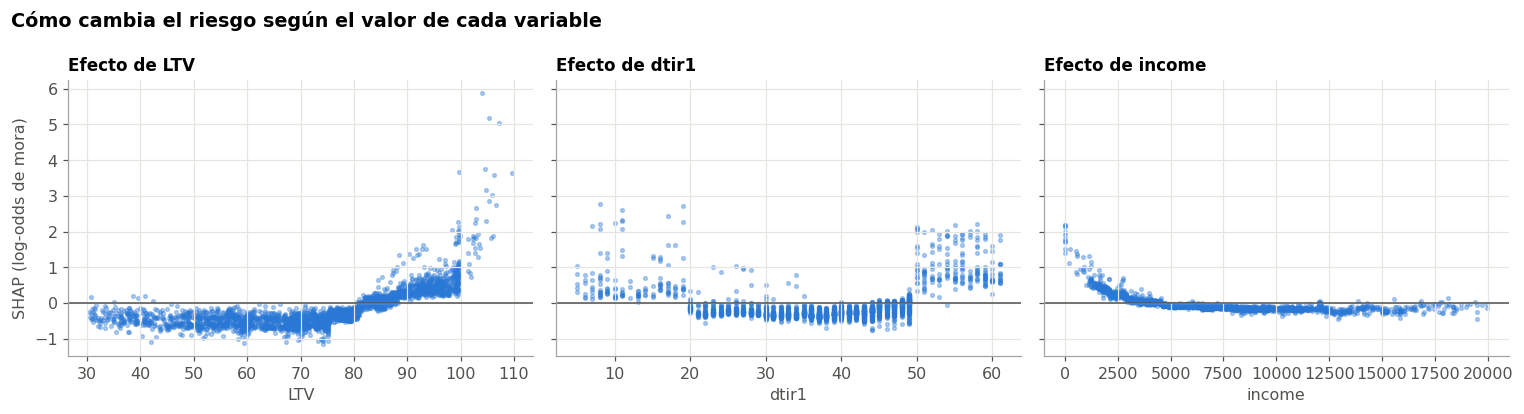

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, col, rango in zip(axes, ["LTV", "dtir1", "income"], [(30, 110), (5, 61), (0, 20000)]):
    j = FEATURES.index(col)
    xv = datos_vista[col].astype(float).to_numpy()
    ok = ~np.isnan(xv) & (xv >= rango[0]) & (xv <= rango[1])
    ax.scatter(xv[ok], valores[ok, j], s=6, alpha=0.35, color=AZUL)
    ax.axhline(0, color=TINTA2, lw=1)
    ax.set_xlabel(col); ax.set_title(f"Efecto de {col}", fontsize=11)
axes[0].set_ylabel("SHAP (log-odds de mora)")
fig.suptitle("Cómo cambia el riesgo según el valor de cada variable", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout()
guardar(fig, "f11_shap_dependencia.png")

Las tres relaciones van en la dirección esperada y tienen umbrales: el riesgo sube a partir de un LTV de ~80% y de una deuda/ingreso de ~50%, y baja con el ingreso. Son los mismos cortes que encontró la mejor regla, pero el modelo además los combina con el resto de las variables.

### Ejemplo: explicación de un rechazo

Una solicitud del test que el modelo rechaza y que efectivamente entró en mora.

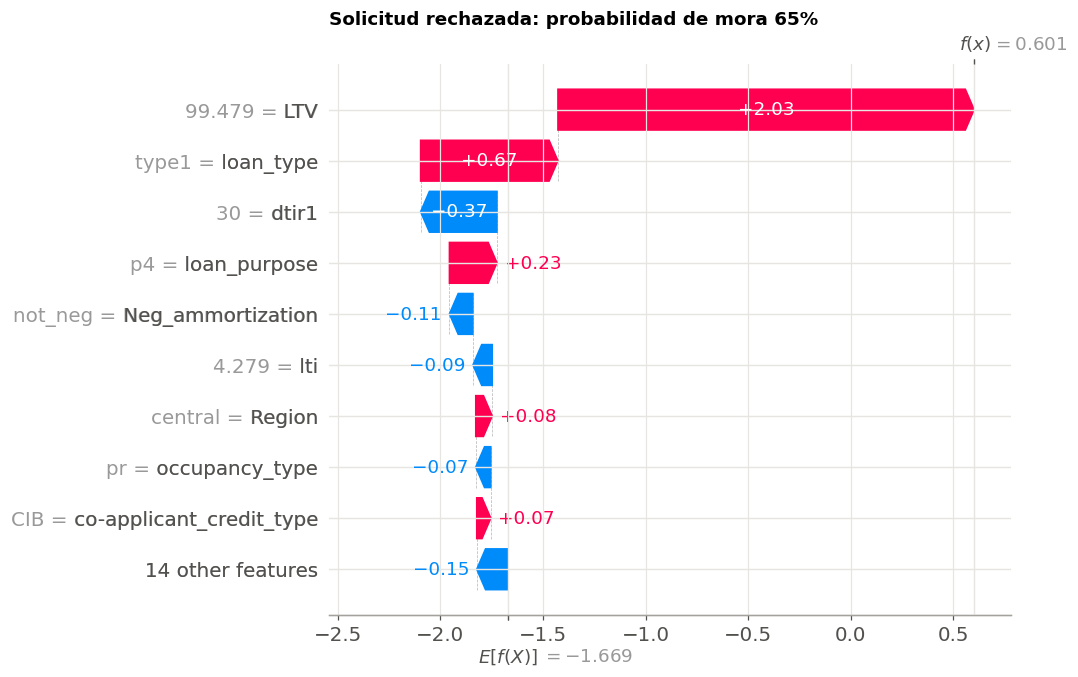

Probabilidad de mora: 64.6%   umbral económico de esta solicitud: 9.2%
Principales motivos del rechazo: LTV = 99.47916667; loan_type = type1; loan_purpose = p4


In [41]:
rech_m = politicas[MOD20][muestra.index.to_numpy()]
y_m = y_test[muestra.index.to_numpy()]
candidatos = np.where(rech_m & (y_m == 1))[0]
p_m = modelo.predict_proba(muestra)[:, 1]
caso = candidatos[np.argsort(np.abs(p_m[candidatos] - np.median(p_m[candidatos])))[0]]
plt.figure()
shap.plots.waterfall(expl[caso], max_display=10, show=False)
plt.title(f"Solicitud rechazada: probabilidad de mora {p_m[caso]:.0%}", loc="left", fontsize=12, fontweight="bold")
guardar(plt.gcf(), "f12_shap_caso_rechazado.png")


def motivos(i, k=3):
    s = pd.Series(valores[i], index=FEATURES).sort_values(ascending=False).head(k)
    return [f"{c} = {datos_vista.iloc[i][c]}" for c in s.index]


print(f"Probabilidad de mora: {p_m[caso]:.1%}   umbral económico de esta solicitud: "
      f"{MARGEN / (MARGEN + lgd_test[muestra.index[caso]]):.1%}")
print("Principales motivos del rechazo:", "; ".join(motivos(caso)))

Cada barra suma (rojo) o resta (azul) riesgo a partir del valor promedio del modelo. En este caso pesan un LTV de 99%, el tipo y el propósito del préstamo. Los tres motivos principales de cada rechazo se pueden traducir a una frase para el solicitante, por ejemplo: "el monto es alto en relación con el valor de la propiedad".

---
# 8. Impacto, riesgos y ética

## 8.1 Sensibilidad a los supuestos

Recalculamos la ventaja sobre la mejor regla para 12 combinaciones de margen (2% a 5%) y recupero (60% a 80%), volviendo a optimizar la regla en cada caso.

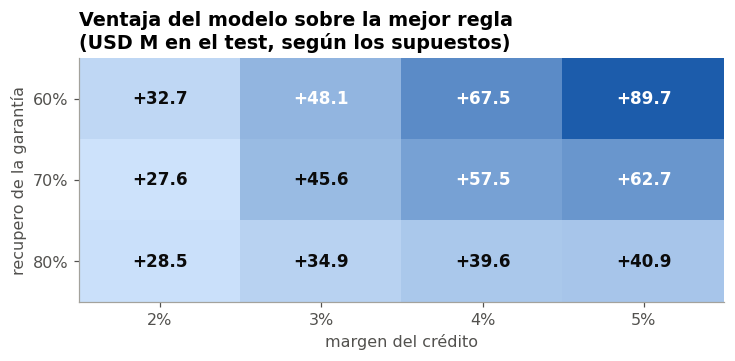

Ventaja positiva en 12 de 12 escenarios


In [42]:
sens = []
for mg in [0.02, 0.03, 0.04, 0.05]:
    for rc in [0.60, 0.70, 0.80]:
        ld, lt = lgd(dev, rc), lgd(test, rc)
        mejor_r = max(((f["LTV >"], f["DTI >"], f["modo"]) for _, f in grilla.iterrows()),
                      key=lambda g: resultado(y_dev, regla(dev, *g), monto_dev, ld, mg)["resultado neto"])
        r_regla = resultado(y_test, regla(test, *mejor_r), monto_test, lt, mg)
        r_mod = resultado(y_test, rechazo_economico(p_test, lt, mg), monto_test, lt, mg)
        sens.append({"margen": mg, "recupero": rc, "LGD medio": lt.mean(),
                     "rechazo modelo %": r_mod["% rechazado"], "rechazo regla %": r_regla["% rechazado"],
                     "ventaja del modelo (USD M)": (r_mod["resultado neto"] - r_regla["resultado neto"]) / 1e6})
sens = tabla(pd.DataFrame(sens), "t16_sensibilidad.csv")

piv = sens.pivot(index="recupero", columns="margen", values="ventaja del modelo (USD M)")
fig, ax = plt.subplots(figsize=(6.8, 3.4))
im = ax.imshow(piv.values, cmap=matplotlib.colors.LinearSegmentedColormap.from_list("az", ["#cde2fb", "#1c5cab"]), aspect="auto")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        val = piv.values[i, j]
        ax.text(j, i, f"+{val:.1f}" if val >= 0 else f"{val:.1f}", ha="center", va="center", fontsize=11,
                color="white" if val > piv.values.mean() else TINTA, fontweight="bold")
ax.set_xticks(range(piv.shape[1]), [f"{c:.0%}" for c in piv.columns]); ax.set_yticks(range(piv.shape[0]), [f"{r:.0%}" for r in piv.index])
ax.set_xlabel("margen del crédito"); ax.set_ylabel("recupero de la garantía")
ax.set_title("Ventaja del modelo sobre la mejor regla\n(USD M en el test, según los supuestos)")
ax.grid(False)
fig.tight_layout()
guardar(fig, "f13_sensibilidad.png")
print(f"Ventaja positiva en {(sens['ventaja del modelo (USD M)'] > 0).sum()} de {len(sens)} escenarios")

La ventaja del modelo es positiva en los 12 escenarios (USD 28 a 90 M en test). Lo que sí cambia es cuánto conviene rechazar (10% a 46%), y por eso fijamos el tope.

## 8.2 Simulación a tres años

**Volumen:** el del dataset, un año de un originador. Son 148.670 solicitudes, de las cuales el modelo evalúa 133.337 (las que no tienen tasación van a revisión manual). Con un monto medio de USD 330.000, son unos USD 44.000 M por año. Comparamos contra la mejor regla con el mismo tope.

El resultado del test es un techo, así que lo ajustamos con tres escenarios:

| | Pesimista | Base | Optimista |
|---|---|---|---|
| Margen | 2% | 3% | 4% |
| Recupero | 80% | 70% | 60% |
| Parte de la ventaja del test que se mantiene en la realidad (un modelo suele rendir peor con datos reales) | 50% | 75% | 100% |

En los tres casos, los primeros 3 meses son un piloto sin beneficio. Para el valor actual neto
(VAN) descontamos los flujos a un costo de capital de 12% anual.

Costos estimados:

| Concepto | Tipo | USD |
|---|---|---|
| Desarrollo (4 personas, ~3 meses) | CAPEX | 90.000 |
| Integración con el sistema de originación | CAPEX | 40.000 |
| Validación independiente | CAPEX | 20.000 |
| Infraestructura en la nube | OPEX anual | 12.000 |
| Monitoreo y reentrenamiento | OPEX anual | 35.000 |
| Auditoría anual | OPEX anual | 15.000 |
| Revisión manual de casos dudosos | OPEX anual | 8.000 |

In [43]:
SOLICITUDES_DATASET = len(crudo)          # un año de solicitudes (2019)
VOLUMEN_MODELO = len(datos)               # las que evalúa el modelo; el resto va a revisión manual
CAPEX = 90_000 + 40_000 + 20_000
OPEX = 12_000 + 35_000 + 15_000 + 8_000
MESES_PILOTO = 3
COSTO_CAPITAL = 0.12      # retorno anual exigido para descontar los flujos
ESCENARIOS = {"Pesimista": (0.02, 0.80, 0.50), "Base": (0.03, 0.70, 0.75), "Optimista": (0.04, 0.60, 1.00)}
grilla_tope = grilla[grilla["% rechazado"] <= TOPE]   # el % de rechazo de una regla no depende de margen ni recupero

esc = []
for nombre_e, (mg, rc, captura) in ESCENARIOS.items():
    ld, lt = lgd(dev, rc), lgd(test, rc)
    corte_e = corte_tope(oof[elegido], ld, monto_dev, margen=mg)
    r_mod = resultado(y_test, rechazo_con_corte(p_test, lt, monto_test, corte_e, mg), monto_test, lt, mg)
    g = max(((f["LTV >"], f["DTI >"], f["modo"]) for _, f in grilla_tope.iterrows()),
            key=lambda g: resultado(y_dev, regla(dev, *g), monto_dev, ld, mg)["resultado neto"])
    r_reg = resultado(y_test, regla(test, *g), monto_test, lt, mg)
    por_solicitud = (r_mod["resultado neto"] - r_reg["resultado neto"]) / len(test)
    plena = por_solicitud * VOLUMEN_MODELO                       # ventaja anual si rindiera como en el test
    anual = plena * captura
    beneficio = [anual * (12 - MESES_PILOTO) / 12, anual, anual]
    costos = [CAPEX + OPEX, OPEX, OPEX]
    esc.append({"escenario": nombre_e, "margen": mg, "recupero": rc, "captura": captura,
                "rechazo modelo %": r_mod["% rechazado"], "regla con tope": describir_regla(dict(zip(["LTV >", "DTI >", "modo"], g))),
                "ventaja por solicitud (USD)": por_solicitud,
                "ventaja anual plena (USD M)": plena / 1e6, "ventaja anual con captura (USD M)": anual / 1e6,
                "ventaja / volumen evaluado (%)": anual / (monto_test.mean() * VOLUMEN_MODELO) * 100,
                "neto año 1 (USD M)": (beneficio[0] - costos[0]) / 1e6,
                "neto 3 años (USD M)": (sum(beneficio) - sum(costos)) / 1e6,
                # VAN: CAPEX al inicio y flujos anuales descontados al costo de capital
                "VAN 3 años (USD M)": (-CAPEX + sum((b - OPEX) / (1 + COSTO_CAPITAL) ** (t + 1)
                                                   for t, b in enumerate(beneficio))) / 1e6,
                "captura mínima para cubrir el año 1 (%)": costos[0] / (plena * (12 - MESES_PILOTO) / 12) * 100})
esc = tabla(pd.DataFrame(esc).set_index("escenario"), "t17_negocio_escenarios.csv", index=True)

escala = VOLUMEN_MODELO / len(test)
negocio = tabla(pd.DataFrame({"valor": {
    "solicitudes en el dataset (un año)": SOLICITUDES_DATASET,
    "solicitudes evaluadas por el modelo": VOLUMEN_MODELO,
    "monto medio por solicitud (USD)": monto_test.mean(),
    "volumen evaluado por año (USD M)": monto_test.mean() * VOLUMEN_MODELO / 1e6,
    "ventaja anual plena, escenario base sin captura (USD M)": esc.loc["Base", "ventaja anual plena (USD M)"],
    "IC 95% inferior, plena (USD M)": ic.loc["dif con tope 20%", "IC 95% inferior"] * escala / 1e6,
    "IC 95% superior, plena (USD M)": ic.loc["dif con tope 20%", "IC 95% superior"] * escala / 1e6,
    "CAPEX (USD)": CAPEX, "OPEX anual (USD)": OPEX,
}}), "t17_negocio_anual.csv", index=True)
for k, val in negocio["valor"].items():
    print(f"{k:<58} {val:>16,.1f}")
print()
esc.round(2)

solicitudes en el dataset (un año)                                148,670.0
solicitudes evaluadas por el modelo                               133,337.0
monto medio por solicitud (USD)                                   331,331.0
volumen evaluado por año (USD M)                                   44,178.7
ventaja anual plena, escenario base sin captura (USD M)               224.0
IC 95% inferior, plena (USD M)                                        203.9
IC 95% superior, plena (USD M)                                        243.1
CAPEX (USD)                                                       150,000.0
OPEX anual (USD)                                                   70,000.0



,margen,recupero,captura,rechazo modelo %,regla con tope,ventaja por solicitud (USD),ventaja anual plena (USD M),ventaja anual con captura (USD M),ventaja / volumen evaluado (%),neto año 1 (USD M),neto 3 años (USD M),VAN 3 años (USD M),captura mínima para cubrir el año 1 (%)
escenario,,,,,,,,,,,,,
Pesimista,0.0200,0.8000,0.5000,19.3800,rechazar si LTV > 95 o DTI > 50,898.3000,119.7800,59.8900,0.1400,44.7000,164.3300,130.1500,0.2400
Base,0.0300,0.7000,0.7500,19.4200,rechazar si LTV > 95 o DTI > 50,"1,680.0500",224.0100,168.0100,0.3800,125.7900,461.6700,365.7100,0.1300
Optimista,0.0400,0.6000,1.0000,19.4800,rechazar si LTV > 95 o DTI > 50,"2,903.5300",387.1500,387.1500,0.8800,290.1400,"1,064.3000",843.1300,0.0800


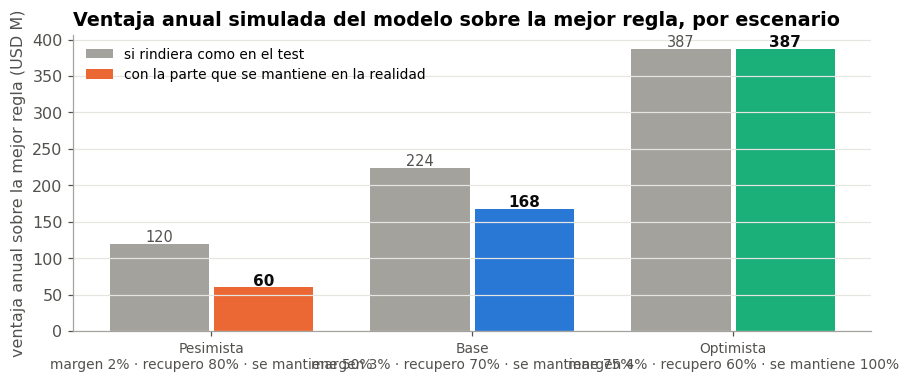

In [44]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
cols = [NARANJA, AZUL, AQUA]
x = np.arange(3)
ax.bar(x - 0.2, esc["ventaja anual plena (USD M)"], 0.38, color=GRIS, label="si rindiera como en el test")
ax.bar(x + 0.2, esc["ventaja anual con captura (USD M)"], 0.38, color=cols, label="con la parte que se mantiene en la realidad")
for i, (a_, b_) in enumerate(zip(esc["ventaja anual plena (USD M)"], esc["ventaja anual con captura (USD M)"])):
    ax.text(i - 0.2, a_ + 3, f"{a_:.0f}", ha="center", fontsize=9.5, color=TINTA2)
    ax.text(i + 0.2, b_ + 3, f"{b_:.0f}", ha="center", fontsize=10, color=TINTA, fontweight="bold")
ax.set_xticks(x, [f"{n}\nmargen {m:.0%} · recupero {r:.0%} · se mantiene {c:.0%}" for n, (m, r, c) in ESCENARIOS.items()], fontsize=9)
ax.set_ylabel("ventaja anual sobre la mejor regla (USD M)")
ax.set_title("Ventaja anual simulada del modelo sobre la mejor regla, por escenario")
ax.legend(loc="upper left", fontsize=9); ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "f15_escenarios.png")

Aun en el escenario pesimista, la ventaja anual es de decenas de millones de dólares contra USD 220.000 de costo el primer año, y alcanza con que se mantenga una parte mínima de la ventaja para cubrirlo (columna "captura mínima"). Medida contra el volumen prestado es menos del 1%: una mejora chica sobre una cartera muy grande.

El riesgo del proyecto no es el costo sino que el modelo rinda igual con datos reales; por eso recomendamos un piloto. Además, la mora del dataset (16%) es alta para una cartera hipotecaria: con menos mora, la ventaja en dólares sería menor.

## 8.3 Auditoría por grupo

El modelo no usa género ni edad, pero podría reconstruirlos a partir de otras variables. Por eso miramos, para cada grupo, la tasa de mora real y cuántos buenos pagadores quedan rechazados.

In [45]:
aud = []
rech = politicas[MOD20]
for col in ["Gender", "age", "Region"]:
    for g, idx in test.groupby(col).groups.items():
        idx = np.asarray(idx)
        yy, rr = y_test[idx], rech[idx]
        aud.append({"atributo": col, "grupo": g, "solicitudes": len(idx), "tasa de mora real %": yy.mean() * 100,
                    "rechazados %": rr.mean() * 100,
                    "moras detectadas % (recall)": rr[yy == 1].mean() * 100 if (yy == 1).any() else np.nan,
                    "buenos pagadores rechazados % (FPR)": rr[yy == 0].mean() * 100})
aud = tabla(pd.DataFrame(aud), "t18_auditoria_grupos.csv")
aud.round(1)

,atributo,grupo,solicitudes,tasa de mora real %,rechazados %,moras detectadas % (recall),buenos pagadores rechazados % (FPR)
0,Gender,Female,6014,16.0000,19.9000,53.4000,13.5000
1,Gender,Joint,9424,11.5000,13.6000,52.2000,8.6000
2,Gender,Male,9444,17.3000,21.8000,56.3000,14.5000
3,Gender,Sex Not Available,8453,19.4000,22.9000,55.1000,15.2000
4,age,25-34,4227,13.6000,24.3000,59.5000,18.8000
5,age,35-44,7479,13.5000,19.4000,57.7000,13.4000
6,age,45-54,7886,15.7000,18.7000,55.2000,11.9000
7,age,55-64,7353,18.3000,17.9000,52.7000,10.1000
8,age,65-74,4574,17.8000,17.8000,49.3000,11.0000
9,age,<25,315,21.3000,38.1000,70.1000,29.4000


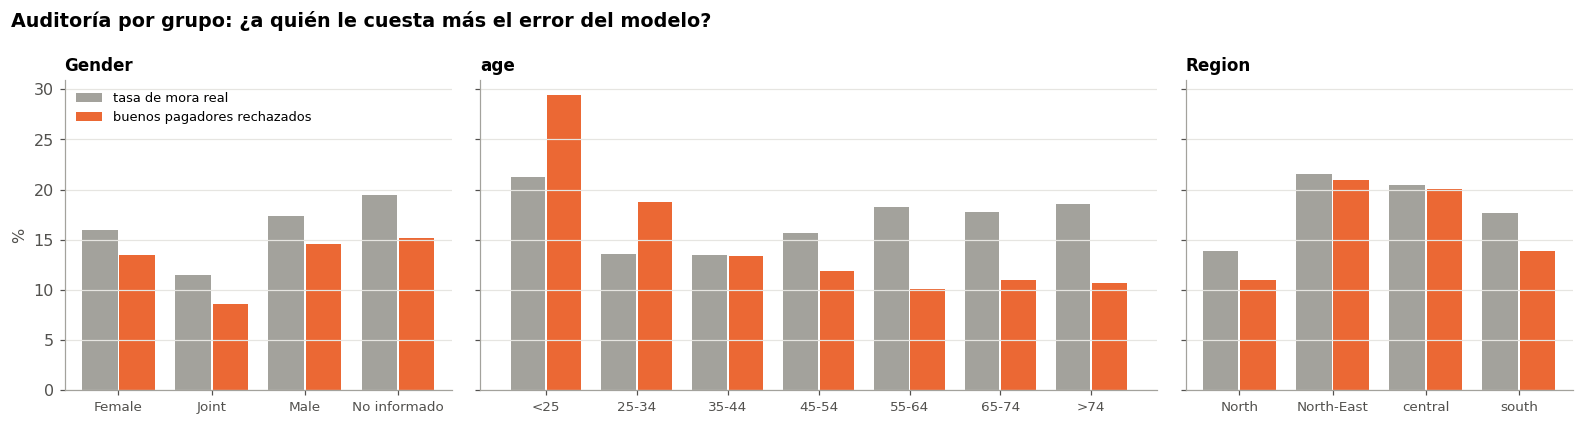

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.9), sharey=True, gridspec_kw={"width_ratios": [4, 7, 4]})
for ax, col in zip(axes, ["Gender", "age", "Region"]):
    a = aud[aud["atributo"] == col]
    if col == "age":
        orden_e = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]
        a = a.set_index("grupo").loc[orden_e].reset_index()
    x = np.arange(len(a))
    ax.bar(x - 0.2, a["tasa de mora real %"], 0.38, color=GRIS, label="tasa de mora real")
    ax.bar(x + 0.2, a["buenos pagadores rechazados % (FPR)"], 0.38, color=NARANJA, label="buenos pagadores rechazados")
    ax.set_xticks(x, [str(g).replace("Sex Not Available", "No informado") for g in a["grupo"]], fontsize=8.8, rotation=0)
    ax.set_title(col, fontsize=11); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("%"); axes[0].legend(fontsize=8.5, loc="upper left")
fig.suptitle("Auditoría por grupo: ¿a quién le cuesta más el error del modelo?", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout()
guardar(fig, "f14_auditoria.png")

- **Género y región:** los rechazos acompañan a la tasa de mora real de cada grupo.
- **Edad:** los de 25-34 años tienen menos mora (13,6%) que los de 55-64 (18,3%), pero más buenos pagadores rechazados (18,8% contra 10,1%). Los menores de 25 son pocos (315) pero tienen el valor más alto (29%). Creemos que se debe a que ganan menos en relación con lo que piden.

Decidimos no corregirlo con umbrales distintos por edad, porque eso sería usar la edad para decidir. Lo dejamos como riesgo: habría que revisarlo con el área legal y seguirlo en cada reentrenamiento.

## 8.4 Riesgos

| Riesgo | Mitigación |
|---|---|
| Dataset con artefactos y en parte sintético | Reentrenar con datos reales del banco |
| Sin fechas (todo es de 2019) | Validar en otro período y monitorear todos los meses |
| Supuestos económicos sin fuente propia | Sensibilidad (8.1); validar con finanzas |
| La pérdida no considera el seguro hipotecario, habitual en EE.UU. con LTV mayor a 80% | Puede sobreestimar el valor en dólares |
| Códigos sin documentar (p1-p4, type1-type3) | Validar con el negocio |
| Diferencia por edad | Auditoría en cada reentrenamiento |
| El banco solo ve la mora de los que aprueba | Aprobar una pequeña parte fuera del modelo para seguir aprendiendo |
| Privacidad | Minimización de datos y control de accesos (Ley 25.326) |

## 8.5 Escalabilidad

El modelo entrena en segundos y puntúa una solicitud en milisegundos. El mismo pipeline sirve para otros créditos con garantía.

---
# 9. Conclusiones

1. El hallazgo más importante fue de datos: un 10% del dataset es un bloque con 100% de mora que infla cualquier métrica (ROC-AUC 0,89 en lugar de 0,81). Lo excluimos.
2. XGBoost, elegido con una regla fijada de antemano, empata con HistGradientBoosting y supera claramente a la logística.
3. Con el mismo tope de 20%, detecta el 55% de las moras contra el 31% de la mejor regla LTV/DTI, y mejora el resultado simulado en USD 56 M sobre el test (IC 95%: 51 a 61 M).
4. El tope se puede aplicar en la operación diaria con un corte fijo.
5. H1, H2 y H3 se sostienen; H4 no.
6. Para mejorar el modelo hacen falta otras variables más que más filas.
7. Hay una diferencia por edad que dejamos declarada como riesgo.

**Recomendación:** no desplegarlo todavía. Reentrenar con datos reales y fechados, validar margen y recupero con finanzas, revisar la diferencia por edad y hacer un piloto de 3 meses en el que el modelo recomienda y el analista decide.

---
# Resumen de resultados

In [47]:
resumen = {
    "filas originales": len(crudo), "filas excluidas (artefacto)": int(artefacto.sum()),
    "filas para modelar": len(datos), "tasa de mora (datos válidos)": datos[TARGET].mean(),
    "modelo elegido": elegido, "parámetros": PARAMS,
    "PR-AUC test (media 5 semillas)": pr_sem.mean(), "PR-AUC test desvío": pr_sem.std(),
    "ROC-AUC test": roc_auc_score(y_test, p_test),
    "mejor regla": TXT_MEJOR_REGLA,
}
for k, val in resumen.items():
    print(f"{k:<35} {val}")
print()
print(comparacion[["% rechazado", "recall (moras detectadas)", "pérdida crediticia", "resultado neto"]].round(1).to_string())
print("\nNotebook ejecutado completo.")

filas originales                    148670
filas excluidas (artefacto)         15333
filas para modelar                  133337
tasa de mora (datos válidos)        0.15981310513960867
modelo elegido                      XGBoost
parámetros                          {}
PR-AUC test (media 5 semillas)      0.6207535201432302
PR-AUC test desvío                  0.00036349645231868933
ROC-AUC test                        0.8130179840274122
mejor regla                         rechazar si LTV > 85 o DTI > 50

                                                % rechazado  recall (moras detectadas)  pérdida crediticia   resultado neto
Aprobar todo                                         0.0000                     0.0000    230,291,800.0000  51,250,460.0000
Regla propuesta (LTV>80 y DTI>45)                    9.8000                    16.6000    170,459,100.0000  87,167,535.0000
Mejor regla (LTV > 85 o DTI > 50)                   30.5000                    46.7000     69,528,700.0000 133,517,585.0000